# Лабораторная работа № 3
## Свёрточные нейронные сети и перенос обучения для классификации изображений. Часть 1: собственная CNN, бинарная классификация
### Вариант 7

Набор данных: PlantVillage, листья картофеля. Бинарная задача: класс 0 - фитофтороз (`Potato___Late_blight`), класс 1 - здоровый лист (`Potato___healthy`). Класс 2 (`Potato___Early_blight`) в бинарной задаче исключается, все три класса используются во второй части работы, ноутбуке `nn-lab-3-transfer.ipynb`.

В этом ноутбуке выполняются задачи 1-6 и 9 (для бинарной модели).

## Цель работы

Получить практические навыки подготовки наборов изображений, построения и обучения свёрточных нейронных сетей (CNN), оценки качества моделей классификации, применения аугментации и регуляризации, а также использования предварительно обученных на ImageNet моделей с переносом обучения (transfer learning) и тонкой настройкой (fine-tuning).

## Задание

1. Изучить структуру выбранного набора изображений и сформировать три класса согласно индивидуальному варианту.
2. Подготовить данные: проверить изображения и метки, привести изображения к единому размеру и формату, разделить данные на обучающую, валидационную и тестовую выборки.
3. Построить и обучить собственную CNN для бинарной классификации классов 0 и 1.
4. Исследовать влияние архитектуры сети, числа фильтров, глубины сети, оптимизатора и Dropout на качество и устойчивость обучения.
5. Применить аугментацию только к обучающим данным и сравнить результаты с обучением без аугментации.
6. Выбрать и сохранить лучшую модель бинарной классификации.
7. Построить трёхклассовый классификатор на основе предварительно обученной на ImageNet свёрточной сети.
8. Сравнить два режима transfer learning: обучение классификационной "головы" при замороженной свёрточной основе и fine-tuning с частичной разморозкой основы.
9. Оценить модели на отложенной тестовой выборке, сравнить метрики, построить графики обучения и сформулировать выводы.

## Настройка

In [1]:
import os
from pathlib import Path

# Бэкенд Keras нужно выбрать до импорта keras
os.environ["KERAS_BACKEND"] = "torch"

import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Одно значение для всех ноутбуков, чтобы результаты воспроизводились
SEED = 42
keras.utils.set_random_seed(SEED)

# Ноутбук лежит в labs/labN/src, поэтому пути строим от него
LAB_DIR = Path.cwd().parent
DATA_DIR = LAB_DIR.parent / "data"
FIGURES_DIR = LAB_DIR / "figures"
RESULTS_DIR = LAB_DIR / "results"
MODELS_DIR = LAB_DIR / "models"
for output_dir in (FIGURES_DIR, RESULTS_DIR, MODELS_DIR):
    output_dir.mkdir(exist_ok=True)

# Крупный шрифт: графики должны читаться на слайдах
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 200, "font.size": 12, "axes.grid": True})

Дополнительные импорты и параметры эксперимента. Все константы собраны здесь, чтобы условия обучения были видны сразу и были одинаковы для всех моделей.

In [2]:
import gc
import hashlib
import platform
import subprocess
import time
import warnings
from importlib.metadata import version

import seaborn as sns
from matplotlib.ticker import MaxNLocator
from IPython.display import display
from PIL import Image
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

# Файл весов хранит и состояние оптимизатора; при загрузке весов для предсказаний
# оно не нужно, и Keras предупреждает об этом. Предупреждение безвредно, скрываем его
warnings.filterwarnings("ignore", message="Skipping variable loading for optimizer")

# Префикс имён файлов этого ноутбука в figures, results и models
NOTEBOOK_PREFIX = "binary"

IMAGE_DIR = DATA_DIR / "plantvillage"
DATASET_URL = "https://www.kaggle.com/datasets/emmarex/plantdisease"

# Три класса варианта 7: номер класса равен позиции папки в списке
CLASS_FOLDERS = ["Potato___Late_blight", "Potato___healthy", "Potato___Early_blight"]
CLASS_NAMES = ["Фитофтороз", "Здоровый", "Альтернариоз"]

# Размер входа сети: рекомендуемые 224 x 224 пикселя
IMAGE_SIZE = 224

# Два снимка с корреляцией уменьшенных копий выше порога считаются снимками
# одного листа и попадают в одну выборку (порог обоснован в анализе данных)
NEAR_DUPLICATE_CORRELATION = 0.93

# Цвета графиков, одинаковые во всех рисунках
TRAIN_COLOR = "#2a78d6"
VAL_COLOR = "#eb6834"
TEST_COLOR = "#52514e"
CLASS_COLORS = ["#8c564b", "#1baf7a", "#d4a017"]

# Бинарная задача: только классы 0 и 1. Положительный класс - метка 1 (здоровый лист)
BINARY_LABELS = [0, 1]
POSITIVE_LABEL = 1

# Общие условия обучения всех CNN
BATCH_SIZE = 32
LEARNING_RATE = 0.001
MAX_EPOCHS = 50
PATIENCE = 8

# Аугментация делает каждую эпоху другой, val loss сходится медленнее и сильнее
# колеблется, поэтому для сетей с аугментацией больше эпох и терпения
AUG_MAX_EPOCHS = 100
AUG_PATIENCE = 15

# Допуск при выборе модели по val loss. Валидационная выборка бинарной задачи мала
# (около 170 снимков), и повтор того же обучения с другим seed меняет val loss
# примерно на сотые доли. Модели, которые отличаются меньше допуска, считаются
# равными, и из них берётся более простая (меньше параметров). Насколько велик
# реальный разброс, проверяется отдельным экспериментом с тремя seed.
LOSS_TOLERANCE = 0.01

In [3]:
# Версии библиотек и оборудование: нужны, чтобы повторить эксперимент
for package in ["keras", "torch", "numpy", "pandas", "scikit-learn", "pillow", "matplotlib", "seaborn"]:
    print(f"{package}: {version(package)}")
print("Python:", platform.python_version())
print("Бэкенд Keras:", keras.backend.backend())
# Тензор Keras на бэкенде torch знает своё устройство: cuda:0 значит, что считает видеокарта
print("Устройство вычислений:", keras.ops.zeros(1).device)
gpu_query = subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total", "--format=csv,noheader"],
                           capture_output=True, text=True)
print("Видеокарта:", gpu_query.stdout.strip() or "не найдена")
print("Процессор:", platform.processor(), "-", os.cpu_count(), "логических ядер")
print("ОС:", platform.platform())

keras: 3.15.1
torch: 2.12.1+cu126
numpy: 2.5.4
pandas: 3.1.0
scikit-learn: 1.9.1
pillow: 13.0.0
matplotlib: 3.11.2
seaborn: 0.13.2
Python: 3.12.10
Бэкенд Keras: torch
Устройство вычислений: cuda:0


Видеокарта: NVIDIA GeForce RTX 4070 Laptop GPU, 8188 MiB
Процессор: AMD64 Family 25 Model 116 Stepping 1, AuthenticAMD - 16 логических ядер
ОС: Windows-11-10.0.26200-SP0


**Результат:** Keras 3.15.1 на бэкенде torch 2.12.1 (CUDA 12.6), вычисления на видеокарте NVIDIA GeForce RTX 4070 Laptop GPU (8 ГБ), Python 3.12.10, Windows 11. Seed 42 фиксирован, но свёртки на видеокарте (cuDNN) выполняются не строго детерминированно, поэтому повторный запуск даёт близкие, но не побитово одинаковые числа. Насколько велик этот разброс, проверяется в эксперименте 3.

## Описание набора данных

**Источник:** [PlantVillage Dataset](https://www.kaggle.com/datasets/emmarex/plantdisease), Kaggle (автор публикации emmarex). Изображения взяты из открытого репозитория PlantVillage ([spMohanty/PlantVillage-Dataset](https://github.com/spMohanty/PlantVillage-Dataset), папка raw/color), который собран проектом PlantVillage (Hughes, Salathe, 2015). Лицензия на Kaggle не указана, набор открыт для учебного использования.

**Описание с сайта (перевод):** "Набор изображений листьев больных растений и соответствующих меток. Набор взят из репозитория spMohanty на GitHub. Создан для системы распознавания болезней растений."

**Что это за данные.** Одна запись - это цветная фотография одного листа картофеля, снятая сверху на однородном сером фоне. Метка записи - папка, в которой лежит файл: она говорит, болен ли лист и какой болезнью. Модель по фотографии листа предсказывает его состояние. Такая модель нужна для ранней диагностики: фермер фотографирует лист телефоном и узнаёт о болезни раньше, чем она распространится по полю.

Классы варианта 7 (остальные 12 папок архива - томат и перец - не используются):

| Номер класса | Папка в архиве | Содержание | Признаки на листе |
|---|---|---|---|
| 0 | `Potato___Late_blight` | фитофтороз картофеля (Phytophthora infestans) | тёмные водянистые пятна без чёткой границы, часто от края листа |
| 1 | `Potato___healthy` | здоровый лист картофеля | равномерно зелёный лист без пятен |
| 2 | `Potato___Early_blight` | альтернариоз, ранняя сухая пятнистость (Alternaria solani) | коричневые сухие пятна с концентрическими кольцами и жёлтым ореолом |

Поля одной записи:

| Поле | Содержание | Значения по данным |
|---|---|---|
| изображение (файл `.JPG`) | фотография листа, 3 канала RGB | 256 x 256 пикселей, яркость каждого канала 0-255 |
| папка | название класса | 3 папки варианта, см. таблицу выше |
| имя файла | уникальный идентификатор и номер снимка (`RS_LB 4640`) | метка серии совпадает с папкой: `RS_LB`, `RS_HL`, `RS_Early.B` |

Размеры, режим RGB и диапазон значений проверяются ниже по самим файлам.

Составляем таблицу файлов трёх классов варианта. Если данных нет, ноутбук сообщает, что и откуда скачать.

In [4]:
# labs/data нет в git, поэтому при первом запуске набор нужно скачать самому
missing_folders = [folder for folder in CLASS_FOLDERS if not (IMAGE_DIR / folder).is_dir()]
if missing_folders:
    raise FileNotFoundError(
        f"Не найдены папки {missing_folders} в {IMAGE_DIR}. Скачайте набор {DATASET_URL} "
        "и скопируйте из папки PlantVillage архива три папки Potato___* в labs/data/plantvillage"
    )

# Таблица файлов: путь относительно IMAGE_DIR и номер класса по папке
file_records = []
for label, folder in enumerate(CLASS_FOLDERS):
    for path in sorted((IMAGE_DIR / folder).iterdir()):
        if path.is_file():
            file_records.append({"file": f"{folder}/{path.name}", "folder": folder, "label": label})
files = pd.DataFrame(file_records)

print("Всего файлов в трёх папках:", len(files))
print("Расширения файлов:", files["file"].str.rsplit(".", n=1).str[-1].value_counts().to_dict())
files.sample(8, random_state=SEED)

Всего файлов в трёх папках: 2152
Расширения файлов: {'JPG': 2152}


,file,folder,label
1505,Potato___Early_blight/5dbb2c15-fc42-4611-b590-...,Potato___Early_blight,2
1660,Potato___Early_blight/8636092c-9357-4b4c-9d2d-...,Potato___Early_blight,2
889,Potato___Late_blight/e2ce6696-9f6e-445c-a6c6-c...,Potato___Late_blight,0
306,Potato___Late_blight/50abdfe1-411f-4afe-8f78-1...,Potato___Late_blight,0
1771,Potato___Early_blight/a29ed5b2-153c-4f0e-a633-...,Potato___Early_blight,2
109,Potato___Late_blight/1d4acd15-f2b9-4a2e-87da-9...,Potato___Late_blight,0
1649,Potato___Early_blight/8435fd63-0136-44f9-8dd4-...,Potato___Early_blight,2
1655,Potato___Early_blight/853f6d7a-836c-4829-ba2c-...,Potato___Early_blight,2


## Анализ данных

### Повреждённые файлы, размеры и формат

Каждый файл открывается и полностью декодируется. Так проверяется, что файл не повреждён, и собираются его размер и цветовой режим.

In [5]:
def inspect_image(relative_path):
    """Открывает файл, проверяет его целостность и возвращает размер, режим и MD5.

    verify() проверяет структуру файла, load() полностью декодирует пиксели и ловит
    обрезанные файлы. MD5 содержимого нужен для поиска точных дубликатов.
    """
    path = IMAGE_DIR / relative_path
    content = path.read_bytes()
    try:
        with Image.open(path) as image:
            image.verify()
        with Image.open(path) as image:
            image.load()
            return {"readable": True, "width": image.width, "height": image.height,
                    "mode": image.mode, "md5": hashlib.md5(content).hexdigest()}
    except Exception as error:
        print("Повреждённый файл:", relative_path, error)
        return {"readable": False, "width": 0, "height": 0, "mode": "", "md5": hashlib.md5(content).hexdigest()}


inspection = pd.DataFrame([inspect_image(relative_path) for relative_path in files["file"]])
files = pd.concat([files, inspection], axis=1)

print("Повреждённых файлов:", int((~files["readable"]).sum()))
print("Размеры (ширина x высота):", files.groupby(["width", "height"]).size().to_dict())
print("Цветовые режимы:", files["mode"].value_counts().to_dict())

Повреждённых файлов: 0
Размеры (ширина x высота): {(256, 256): 2152}
Цветовые режимы: {'RGB': 2152}


**Результат:** все 2152 файла читаются и полностью декодируются, повреждённых нет. Все изображения одного размера 256 x 256 и в режиме RGB (три канала), поэтому приведение к 224 x 224 x 3 одинаково для всех файлов.

### Количество изображений в каждом классе

,Класс,Папка,Название,Изображений,Доля
0,0,Potato___Late_blight,Фитофтороз,1000,0.4647
1,1,Potato___healthy,Здоровый,152,0.0706
2,2,Potato___Early_blight,Альтернариоз,1000,0.4647


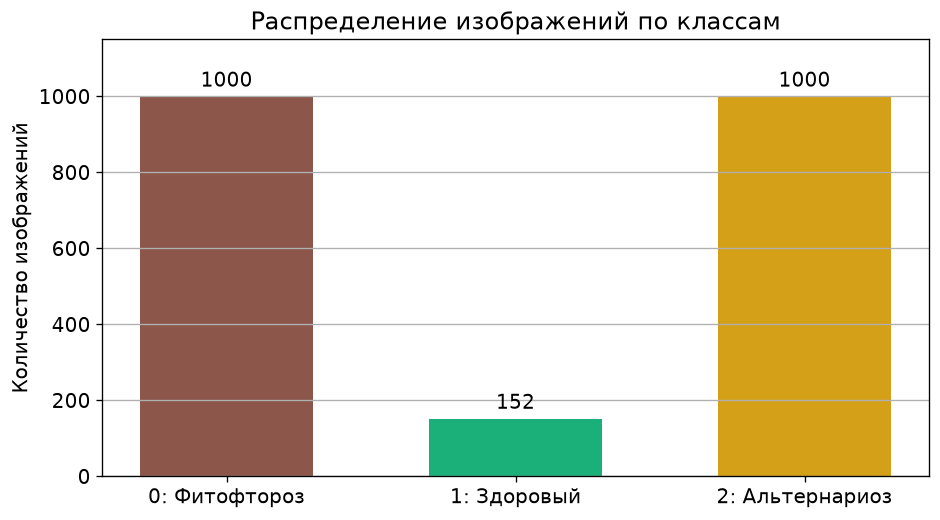

In [6]:
# Количество изображений в каждом классе
class_counts = files["label"].value_counts().sort_index()
count_table = pd.DataFrame({
    "Класс": range(len(CLASS_FOLDERS)),
    "Папка": CLASS_FOLDERS,
    "Название": CLASS_NAMES,
    "Изображений": class_counts.values,
    "Доля": (class_counts.values / len(files)).round(4),
})
display(count_table)

figure, axis = plt.subplots(figsize=(8, 4.5))
bars = axis.bar([f"{label}: {name}" for label, name in enumerate(CLASS_NAMES)], class_counts.values,
                color=CLASS_COLORS, width=0.6)
axis.bar_label(bars, padding=3)
axis.set_ylabel("Количество изображений")
axis.set_title("Распределение изображений по классам")
axis.set_ylim(0, class_counts.max() * 1.15)
axis.grid(axis="x", visible=False)
figure.tight_layout()
figure.savefig(FIGURES_DIR / f"{NOTEBOOK_PREFIX}-class-balance.png")
plt.show()

**Результат:** фитофтороз 1000 снимков (0,4647), здоровые листья 152 (0,0706), альтернариоз 1000 (0,4647). Классы 0 и 2 равны, а здоровых листьев в 6,6 раза меньше: класс 1 редкий, это нужно учитывать при обучении и оценке.

### Корректность меток

Сверяем метку серии съёмки из имени файла с папкой, по которой назначен класс.

In [7]:
# Имя файла содержит метку серии съёмки: RS_LB (late blight), RS_HL (healthy),
# RS_Early.B (early blight). Совпадение метки серии с папкой подтверждает, что
# снимки не перепутаны между папками
files["series_tag"] = files["file"].str.extract(r"___([A-Za-z_.]+?)\s*\d+\.\w+$", expand=False)
files["photo_number"] = files["file"].str.extract(r"(\d+)\.\w+$", expand=False).astype(int)
pd.crosstab(files["folder"], files["series_tag"])

series_tag,RS_Early.B,RS_HL,RS_LB
folder,,,
Potato___Early_blight,1000,0,0
Potato___Late_blight,0,0,1000
Potato___healthy,0,152,0


**Результат:** метка серии в имени файла во всех 2152 случаях совпадает с папкой: `RS_LB` только в папке фитофтороза, `RS_HL` только в папке здоровых, `RS_Early.B` только в папке альтернариоза. Перепутанных меток и посторонних файлов нет.

### Дубликаты и серии почти одинаковых снимков

Если один и тот же лист сфотографирован несколько раз, а снимки попадут в разные выборки, модель на тесте "узнает" знакомый лист, и метрики будут завышены (утечка данных). Поэтому ищем точные дубликаты по MD5 и почти одинаковые снимки по корреляции уменьшенных копий 32 x 32. Пары выше порога `NEAR_DUPLICATE_CORRELATION` объединяются в группы, и группа целиком попадает в одну выборку.

Файлов с точными дубликатами: 0


,Файл 1,Файл 2,Корреляция
0,Potato___Early_blight/5aee3e9f-0469-42e7-8ae7-...,Potato___Early_blight/bc378ba0-533d-42db-a8b2-...,0.9475
1,Potato___Late_blight/8f634ae3-010a-4a08-aae9-2...,Potato___Late_blight/a74a91d8-1a9d-4fa8-bc4b-2...,0.9222
2,Potato___Late_blight/580e8c49-3b1c-46d2-b3f4-6...,Potato___Late_blight/e19d0007-3013-419d-a46a-0...,0.9077
3,Potato___Late_blight/580e8c49-3b1c-46d2-b3f4-6...,Potato___Late_blight/63dc685e-676c-4c9c-8f83-8...,0.9061
4,Potato___Late_blight/55fa97d3-71b6-4487-9757-f...,Potato___Late_blight/699bd8b5-3c57-48c8-be2b-c...,0.9050
5,Potato___Late_blight/0e7f0484-16eb-4183-b702-0...,Potato___Late_blight/e986907b-6948-4c72-93d3-2...,0.9045


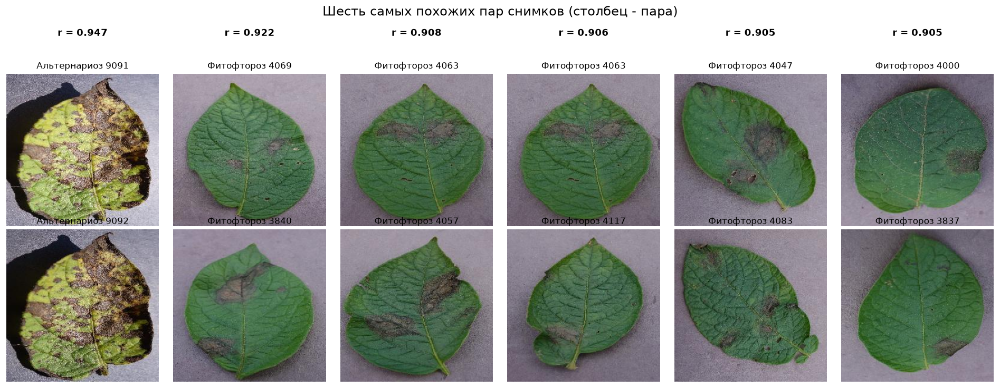

Пар с корреляцией >= 0.93: 1
Групп снимков: 2151 из 2152 файлов


In [8]:
# Точные дубликаты: одинаковое содержимое файла
exact_duplicate_files = int(files["md5"].duplicated(keep=False).sum())
print("Файлов с точными дубликатами:", exact_duplicate_files)


def thumbnail_vector(relative_path):
    """Уменьшает снимок до 32 x 32 в оттенках серого и нормирует его.

    Корреляция таких векторов близка к 1 только у почти одинаковых снимков:
    тот же лист, то же положение, другой кадр серии.
    """
    with Image.open(IMAGE_DIR / relative_path) as image:
        pixels = np.asarray(image.convert("L").resize((32, 32), Image.BILINEAR), dtype=np.float32).ravel()
    return (pixels - pixels.mean()) / (pixels.std() + 1e-6)


thumbnails = np.stack([thumbnail_vector(relative_path) for relative_path in files["file"]])
correlation = thumbnails @ thumbnails.T / thumbnails.shape[1]
np.fill_diagonal(correlation, -1.0)

# Самые похожие пары снимков во всём наборе
upper_i, upper_j = np.triu_indices(len(files), k=1)
pair_values = correlation[upper_i, upper_j]
top_pairs = np.argsort(-pair_values)[:6]
similar_pairs = pd.DataFrame({
    "Файл 1": files["file"].to_numpy()[upper_i[top_pairs]],
    "Файл 2": files["file"].to_numpy()[upper_j[top_pairs]],
    "Корреляция": pair_values[top_pairs].round(4),
})
display(similar_pairs)

figure, axes = plt.subplots(2, 6, figsize=(16, 6))
for column, pair_index in enumerate(top_pairs):
    for row, file_index in enumerate((upper_i[pair_index], upper_j[pair_index])):
        with Image.open(IMAGE_DIR / files.loc[file_index, "file"]) as image:
            axes[row, column].imshow(image)
        axes[row, column].set_title(f"{CLASS_NAMES[files.loc[file_index, 'label']]} {files.loc[file_index, 'photo_number']}",
                                    fontsize=10)
        axes[row, column].axis("off")
    axes[0, column].text(0.5, 1.25, f"r = {pair_values[pair_index]:.3f}", transform=axes[0, column].transAxes,
                         ha="center", fontsize=11, fontweight="bold")
figure.suptitle("Шесть самых похожих пар снимков (столбец - пара)", y=1.02)
figure.tight_layout()
figure.savefig(FIGURES_DIR / f"{NOTEBOOK_PREFIX}-similar-pairs.png", bbox_inches="tight")
plt.show()

# Группы связанных снимков: пары выше порога объединяются в одну группу
near_pairs = np.argwhere(np.triu(correlation >= NEAR_DUPLICATE_CORRELATION))
group_of_file = np.arange(len(files))
for first, second in near_pairs:
    group_of_file[group_of_file == group_of_file[second]] = group_of_file[first]
files["group"] = group_of_file
print(f"Пар с корреляцией >= {NEAR_DUPLICATE_CORRELATION}:", len(near_pairs))
print("Групп снимков:", files["group"].nunique(), "из", len(files), "файлов")

**Результат:** точных дубликатов нет. Самая похожая пара (корреляция 0,9475) - это два кадра одного листа с альтернариозом, снимки 9091 и 9092 с соседними номерами: на рисунке это первый столбец. Следующая пара (0,9222) и все остальные - уже разные листья похожей формы на одинаковом фоне. Поэтому порог 0,93 отделяет снимки одного листа от просто похожих. Найдена одна такая пара, она объединена в группу: 2151 группа на 2152 файла.

### Примеры изображений

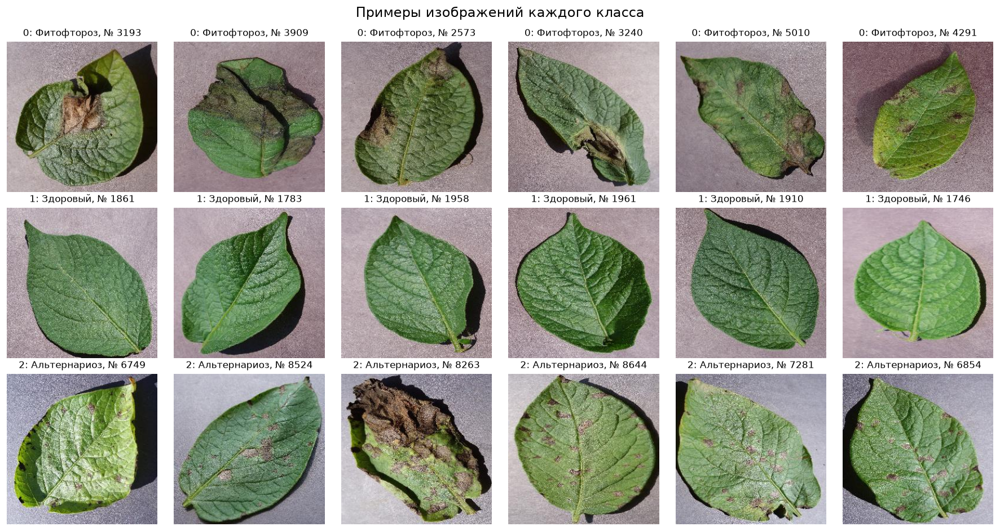

In [9]:
# Шесть случайных примеров каждого класса с подписями
examples_per_class = 6
figure, axes = plt.subplots(len(CLASS_FOLDERS), examples_per_class, figsize=(15, 8))
for label, name in enumerate(CLASS_NAMES):
    sample = files[files["label"] == label].sample(examples_per_class, random_state=SEED)
    for column, (_, record) in enumerate(sample.iterrows()):
        with Image.open(IMAGE_DIR / record["file"]) as image:
            axes[label, column].imshow(image)
        axes[label, column].set_title(f"{label}: {name}, № {record['photo_number']}", fontsize=10)
        axes[label, column].axis("off")
figure.suptitle("Примеры изображений каждого класса")
figure.tight_layout()
figure.savefig(FIGURES_DIR / f"{NOTEBOOK_PREFIX}-examples.png")
plt.show()

**Результат:** внутри класса снимки различаются ориентацией листа, размером, освещением и числом пятен. Фон у всех один (серый, снято в лаборатории), что упрощает задачу, но означает, что на полевых фото качество может быть ниже. Здоровые листья равномерно зелёные. Оба заболевания дают бурые пятна, поэтому фитофтороз и альтернариоз похожи друг на друга больше, чем на здоровый лист: у альтернариоза пятна сухие, с кольцами и желтизной вокруг, у фитофтороза тёмные, расплывчатые, часто от края.

### Баланс классов бинарной задачи

В бинарной задаче остаются классы 0 и 1. Считаем их соотношение.

In [10]:
binary_counts = files.loc[files["label"].isin(BINARY_LABELS), "label"].value_counts().sort_index()
print("Изображений по классам:", {CLASS_NAMES[label]: int(count) for label, count in binary_counts.items()})
print("Доля положительного класса (здоровый):", round(binary_counts[POSITIVE_LABEL] / binary_counts.sum(), 4))
print("Соотношение классов 0 : 1 =", round(binary_counts[0] / binary_counts[1], 2), ": 1")

Изображений по классам: {'Фитофтороз': 1000, 'Здоровый': 152}
Доля положительного класса (здоровый): 0.1319
Соотношение классов 0 : 1 = 6.58 : 1


**Результат:** в бинарной задаче 1000 снимков фитофтороза и 152 здоровых, доля положительного класса 0,1319, соотношение 6,58 : 1. Модель, которая всегда отвечает "фитофтороз", получит Accuracy около 0,87, ничего не распознавая, поэтому основной метрикой качества служит не Accuracy, а Balanced Accuracy, Precision, Recall и ROC-AUC, а при обучении используются веса классов.

## Подготовка данных

### Разбиение на выборки

Разбиение 70 / 15 / 15 со стратификацией по классу, `random_state=SEED`. Делим не отдельные файлы, а группы связанных снимков, чтобы снимки одного листа не оказались в разных выборках. Разбиение выполняется сразу по всем трём классам: тогда оба ноутбука работы используют одни и те же тестовые снимки классов 0 и 1. После разбиения для бинарной задачи оставляем классы 0 и 1. Списки файлов каждой выборки сохраняются в `results`, чтобы эксперимент можно было повторить.

In [11]:
# Каждая группа связанных снимков должна целиком попасть в одну выборку
assert files.groupby("group")["label"].nunique().max() == 1
groups = files.groupby("group", as_index=False)["label"].first()

# Первый шаг: 70% групп в train, 30% во временную часть; стратификация по классу
train_groups, rest_groups = train_test_split(groups, test_size=0.30, stratify=groups["label"],
                                             random_state=SEED)
# Второй шаг: временная часть делится пополам на validation и test
val_groups, test_groups = train_test_split(rest_groups, test_size=0.50, stratify=rest_groups["label"],
                                           random_state=SEED)

split_of_group = {**dict.fromkeys(train_groups["group"], "train"),
                  **dict.fromkeys(val_groups["group"], "validation"),
                  **dict.fromkeys(test_groups["group"], "test")}
files["split"] = files["group"].map(split_of_group)
SPLIT_ORDER = ["train", "validation", "test"]

# Проверка: группы не пересекаются между выборками
assert files.groupby("group")["split"].nunique().max() == 1


def split_distribution(frame, labels):
    """Таблица: число изображений каждого класса и доля положительного класса в выборках."""
    table = pd.crosstab(frame["split"], frame["label"]).reindex(index=SPLIT_ORDER, columns=labels)
    table.columns = [f"{label}: {CLASS_NAMES[label]}" for label in labels]
    table["Всего"] = table.sum(axis=1)
    for label in labels:
        table[f"Доля {label}"] = (table[f"{label}: {CLASS_NAMES[label]}"] / table["Всего"]).round(4)
    return table


print("Все три класса:")
display(split_distribution(files, [0, 1, 2]))

# Бинарная задача: класс 2 исключается после разбиения
binary_files = files[files["label"].isin(BINARY_LABELS)].reset_index(drop=True)
print("Бинарная задача (классы 0 и 1):")
display(split_distribution(binary_files, BINARY_LABELS))

binary_files[["file", "label", "split"]].to_csv(RESULTS_DIR / "binary-split.csv", index=False, encoding="utf-8")

Все три класса:


,0: Фитофтороз,1: Здоровый,2: Альтернариоз,Всего,Доля 0,Доля 1,Доля 2
split,,,,,,,
train,700,106,700,1506,0.4648,0.0704,0.4648
validation,150,23,150,323,0.4644,0.0712,0.4644
test,150,23,150,323,0.4644,0.0712,0.4644


Бинарная задача (классы 0 и 1):


,0: Фитофтороз,1: Здоровый,Всего,Доля 0,Доля 1
split,,,,,
train,700,106,806,0.8685,0.1315
validation,150,23,173,0.8671,0.1329
test,150,23,173,0.8671,0.1329


**Результат:** по трём классам train 1506, validation 323, test 323 снимка; доли классов во всех выборках одинаковы с точностью до 0,001. Бинарная задача: train 806 (700 + 106), validation 173 (150 + 23), test 173 (150 + 23), доля здоровых 0,1315 / 0,1329 / 0,1329. Пара снимков одного листа целиком в одной выборке. Списки файлов сохранены в `results/binary-split.csv`.

### Единый размер, формат и нормализация

Изображения приводятся к 224 x 224 пикселя и трём каналам RGB. Пиксели переводятся в `float32` и делятся на 255, чтобы значения лежали в диапазоне [0; 1]: при входах порядка единицы обучение с начальными весами Keras идёт устойчиво. Статистики для нормировки не обучаются, поэтому утечки из validation и test здесь нет.

In [12]:
def load_images(relative_paths):
    """Читает изображения и приводит их к единому формату: RGB, IMAGE_SIZE x IMAGE_SIZE, uint8.

    convert("RGB") гарантирует три канала даже для серых или RGBA-файлов,
    resize с билинейной интерполяцией уменьшает 256 x 256 до 224 x 224.
    """
    images = np.empty((len(relative_paths), IMAGE_SIZE, IMAGE_SIZE, 3), dtype=np.uint8)
    for index, relative_path in enumerate(relative_paths):
        with Image.open(IMAGE_DIR / relative_path) as image:
            images[index] = np.asarray(image.convert("RGB").resize((IMAGE_SIZE, IMAGE_SIZE), Image.BILINEAR))
    return images


def load_split(split_name):
    """Возвращает X (float32, [0; 1]) и y выбранной выборки бинарной задачи."""
    part = binary_files[binary_files["split"] == split_name]
    images = load_images(part["file"].tolist()).astype("float32") / 255.0
    return images, part["label"].to_numpy()


X_train, y_train = load_split("train")
X_val, y_val = load_split("validation")
X_test, y_test = load_split("test")

for split_name, images, labels in [("train", X_train, y_train), ("validation", X_val, y_val), ("test", X_test, y_test)]:
    print(f"{split_name}: X {images.shape} {images.dtype}, диапазон [{images.min():.1f}; {images.max():.1f}], "
          f"y {np.bincount(labels).tolist()}")

train: X (806, 224, 224, 3) float32, диапазон [0.0; 1.0], y [700, 106]
validation: X (173, 224, 224, 3) float32, диапазон [0.0; 1.0], y [150, 23]
test: X (173, 224, 224, 3) float32, диапазон [0.0; 1.0], y [150, 23]


**Результат:** train 806 изображений, validation и test по 173, каждое 224 x 224 x 3, `float32`, значения в [0; 1].

### Веса классов

Здоровых листьев примерно в 6,6 раза меньше, чем листьев с фитофторозом. Без поправки сеть может почти всегда отвечать "фитофтороз" и всё равно получить высокую Accuracy. Поэтому ошибкам на редком классе даём больший вес. Веса считаются по обучающей выборке функцией `compute_class_weight("balanced")`:

$$ w_c = \frac{n}{K \cdot n_c} $$

где $n$ - число обучающих изображений, $K = 2$ - число классов, $n_c$ - число изображений класса $c$. Validation и test не изменяются. Отдельный эксперимент ниже показывает результат без весов.

In [13]:
class_weight_values = compute_class_weight("balanced", classes=np.array(BINARY_LABELS), y=y_train)
CLASS_WEIGHT = {label: float(weight) for label, weight in zip(BINARY_LABELS, class_weight_values)}

class_weight_table = pd.DataFrame({
    "Класс": [f"{label}: {CLASS_NAMES[label]}" for label in BINARY_LABELS],
    "Изображений в train": [int((y_train == label).sum()) for label in BINARY_LABELS],
    "Вес": [round(CLASS_WEIGHT[label], 4) for label in BINARY_LABELS],
})
class_weight_table["Вес x число"] = (class_weight_table["Изображений в train"] * class_weight_table["Вес"]).round(1)
class_weight_table.to_csv(RESULTS_DIR / "binary-class-weights.csv", index=False, encoding="utf-8")
class_weight_table

,Класс,Изображений в train,Вес,Вес x число
0,0: Фитофтороз,700,0.5757,403.0
1,1: Здоровый,106,3.8019,403.0


**Результат:** вес фитофтороза 0,5757, вес здорового листа 3,8019. Произведение веса на число снимков одинаково (403): оба класса вносят в функцию потерь одинаковый суммарный вклад, хотя здоровых снимков в 6,6 раза меньше.

## Базовая модель

Положительный класс - метка 1, здоровый лист. Для него считаются Precision, Recall, F1 и ROC-AUC:

- Precision - доля действительно здоровых среди листьев, названных здоровыми. Ошибка "больной лист назван здоровым" снижает именно её, а это самая опасная ошибка: болезнь пропущена.
- Recall - доля здоровых листьев, которые модель нашла.
- Balanced Accuracy - среднее Recall двух классов, не зависит от дисбаланса:

$$ BA = \frac{1}{2}\left(\frac{TP}{TP + FN} + \frac{TN}{TN + FP}\right) $$

- ROC-AUC - вероятность того, что случайный здоровый лист получит большую оценку, чем случайный больной; не зависит от порога.

Простейшая модель `Dummy` всегда называет самый частый класс (фитофтороз). Она задаёт нижнюю границу: любая полезная сеть должна быть заметно лучше.

In [14]:
def evaluate_binary(y_true, positive_probabilities, threshold=0.5):
    """Метрики бинарной классификации; положительный класс - метка 1 (здоровый лист)."""
    predicted = (positive_probabilities >= threshold).astype(int)
    return {
        "Accuracy": round(accuracy_score(y_true, predicted), 4),
        "Balanced Accuracy": round(balanced_accuracy_score(y_true, predicted), 4),
        "Precision": round(precision_score(y_true, predicted, zero_division=0), 4),
        "Recall": round(recall_score(y_true, predicted, zero_division=0), 4),
        "F1": round(f1_score(y_true, predicted, zero_division=0), 4),
        "Macro F1": round(f1_score(y_true, predicted, average="macro", zero_division=0), 4),
        "ROC-AUC": round(roc_auc_score(y_true, positive_probabilities), 4),
    }


# Dummy смотрит только на метки, признаки ему не нужны
dummy = DummyClassifier(strategy="most_frequent").fit(np.zeros((len(y_train), 1)), y_train)
dummy_val_probabilities = dummy.predict_proba(np.zeros((len(y_val), 1)))[:, 1]
print("Dummy, validation:", evaluate_binary(y_val, dummy_val_probabilities))

Dummy, validation: {'Accuracy': 0.8671, 'Balanced Accuracy': 0.5, 'Precision': 0.0, 'Recall': 0.0, 'F1': 0.0, 'Macro F1': 0.4644, 'ROC-AUC': 0.5}


**Результат:** `Dummy` на validation: Accuracy 0,8671 при Balanced Accuracy 0,5, Precision, Recall и F1 класса 1 равны 0, ROC-AUC 0,5. Высокая Accuracy получена без распознавания: это доля больших листьев в выборке.

## Эксперименты

Все сети обучаются в одинаковых условиях, если в эксперименте явно не меняется один параметр:

- вход 224 x 224 x 3, пиксели в [0; 1];
- свёрточные блоки Conv2D (ядро 3 x 3, `padding="same"`, ReLU) и MaxPooling2D 2 x 2;
- выход Dense(1, sigmoid) и функция потерь `binary_crossentropy`;
- Adam, скорость обучения 0,001 (стандартное значение Adam, его проверяем в эксперименте с оптимизаторами; для CNN-1 понадобилось 0,0001, см. ниже), batch 32;
- веса классов из `CLASS_WEIGHT`;
- до 50 эпох, `EarlyStopping` по `val_loss` с `restore_best_weights=True` и patience 8. Patience 8: на 170 валидационных снимках val loss колеблется от эпохи к эпохе, и 8 эпох позволяют пережить короткий всплеск, а остановка всё равно наступает задолго до 50 эпох;
- `ModelCheckpoint` сохраняет лучшие по `val_loss` веса каждой модели в `models`, история обучения и время сохраняются в `results`.

Модели сравниваются только на validation. Основной критерий - val loss: на маленькой выборке Accuracy меняется скачками по 1/170, а val loss непрерывен и различает модели, которые обе почти не ошибаются. Если модели отличаются меньше `LOSS_TOLERANCE`, выбирается более простая.

Dropout в первой модели нет: сначала строим кривые и смотрим, есть ли переобучение, затем проверяем Dropout отдельным экспериментом.

In [15]:
# Базовая конфигурация: CNN-1 из таблицы задания, но без Dropout
BASE_CONFIG = {
    "filters": (32, 64),
    "pooling": "flatten",
    "dense_units": 128,
    "dropout": 0.0,
    "optimizer": "adam",
    "learning_rate": LEARNING_RATE,
    "augment": False,
}


def build_augmentation():
    """Слои аугментации. Работают только при обучении, при predict и evaluate пропускают снимок без изменений.

    Лист снят сверху, поэтому отражения и небольшие повороты не меняют диагноз.
    Цвет и яркость не меняем: желтизна и бурые пятна - диагностические признаки.
    """
    return keras.Sequential([
        keras.layers.RandomFlip("horizontal_and_vertical"),
        keras.layers.RandomRotation(0.05),            # до +-18 градусов
        keras.layers.RandomZoom(0.1),                 # масштаб +-10%
        keras.layers.RandomTranslation(0.1, 0.1),     # сдвиг до 10% по каждой оси
    ], name="augmentation")


def make_optimizer(name, learning_rate):
    """Создаёт оптимизатор по имени; SGD берётся с моментом 0,9."""
    if name == "adam":
        return keras.optimizers.Adam(learning_rate)
    if name == "rmsprop":
        return keras.optimizers.RMSprop(learning_rate)
    if name == "sgd":
        return keras.optimizers.SGD(learning_rate, momentum=0.9)
    raise ValueError(f"Неизвестный оптимизатор: {name}")


def build_cnn(config, seed=SEED):
    """Собирает и компилирует CNN для бинарной классификации по словарю config.

    filters - число фильтров в каждом свёрточном блоке (длина = глубина сети),
    pooling - "flatten" или "gap" (GlobalAveragePooling2D) перед полносвязной частью,
    dropout - доля отключаемых нейронов после Dense, 0 - слоя Dropout нет,
    augment - добавить слои аугментации в начало сети.
    """
    # Один seed перед сборкой: начальные веса и случайность аугментации воспроизводимы
    keras.utils.set_random_seed(seed)

    model = keras.Sequential()
    model.add(keras.Input(shape=(IMAGE_SIZE, IMAGE_SIZE, 3)))
    if config["augment"]:
        model.add(build_augmentation())
    for filters in config["filters"]:
        # Свёртка извлекает локальные признаки, пулинг вдвое уменьшает размер карты
        model.add(keras.layers.Conv2D(filters, 3, padding="same", activation="relu"))
        model.add(keras.layers.MaxPooling2D(2))
    if config["pooling"] == "flatten":
        model.add(keras.layers.Flatten())
    else:
        model.add(keras.layers.GlobalAveragePooling2D())
    model.add(keras.layers.Dense(config["dense_units"], activation="relu"))
    if config["dropout"] > 0:
        model.add(keras.layers.Dropout(config["dropout"]))
    # Sigmoid даёт вероятность положительного класса (здоровый лист)
    model.add(keras.layers.Dense(1, activation="sigmoid"))

    model.compile(optimizer=make_optimizer(config["optimizer"], config["learning_rate"]),
                  loss="binary_crossentropy", metrics=["accuracy"])
    return model


def describe_architecture(model):
    """Печатает summary() и функции активации слоёв: summary() их не показывает."""
    model.summary()
    activations = []
    for layer in model.layers:
        activation = getattr(layer, "activation", None)
        if activation is not None:
            activations.append(f"{layer.name}: {activation.__name__}")
    print("Активации по слоям:", ", ".join(activations))


def architecture_text(config):
    """Короткая запись архитектуры для таблицы параметров."""
    blocks = "-".join(str(filters) for filters in config["filters"])
    pooling = "Flatten" if config["pooling"] == "flatten" else "GAP"
    return f"{len(config['filters'])} блока Conv {blocks}, {pooling}, Dense {config['dense_units']}"


def model_file(model_name):
    """Путь к файлу лучших весов модели."""
    return MODELS_DIR / f"binary-{model_name.lower()}.weights.h5"


def training_data(weighting):
    """Обучающие данные и веса классов для выбранного способа учёта дисбаланса.

    balanced - веса классов CLASS_WEIGHT;
    none - без поправки на дисбаланс;
    oversample - снимки редкого класса повторяются, пока классы не сравняются;
    вместе с аугментацией повторы становятся разными снимками.
    """
    if weighting == "balanced":
        return X_train, y_train, CLASS_WEIGHT
    if weighting == "none":
        return X_train, y_train, None
    if weighting == "oversample":
        minority_indices = np.flatnonzero(y_train == POSITIVE_LABEL)
        repeats = int(round((y_train != POSITIVE_LABEL).sum() / len(minority_indices)))
        indices = np.concatenate([np.arange(len(y_train))] + [minority_indices] * (repeats - 1))
        return X_train[indices], y_train[indices], None
    raise ValueError(f"Неизвестный способ: {weighting}")


WEIGHTING_TEXT = {"balanced": "class_weight", "none": "нет", "oversample": "повтор + аугментация"}

# Результаты всех экспериментов
model_configs = {}
model_seeds = {}
trained_histories = {}
experiment_rows = []


def run_experiment(model_name, config, seed=SEED, weighting="balanced", max_epochs=MAX_EPOCHS,
                   use_early_stopping=True, show_architecture=False, patience=PATIENCE):
    """Обучает одну CNN, оценивает её на validation и добавляет строку в таблицу экспериментов.

    Лучшие по val_loss веса сохраняет ModelCheckpoint. Без Early Stopping файл
    перезаписывается каждую эпоху, и в нём остаются веса последней эпохи.
    """
    model = build_cnn(config, seed)
    if show_architecture:
        describe_architecture(model)

    callbacks = [keras.callbacks.ModelCheckpoint(model_file(model_name), monitor="val_loss",
                                                 save_best_only=use_early_stopping, save_weights_only=True)]
    if use_early_stopping:
        callbacks.append(keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience,
                                                       restore_best_weights=True))

    X_fit, y_fit, class_weight = training_data(weighting)
    start_time = time.perf_counter()
    history = model.fit(X_fit, y_fit, validation_data=(X_val, y_val), epochs=max_epochs,
                        batch_size=BATCH_SIZE, class_weight=class_weight, callbacks=callbacks, verbose=0)
    training_seconds = time.perf_counter() - start_time

    # С Early Stopping в модели веса лучшей эпохи, без него - последней
    epochs_done = len(history.history["loss"])
    used_epoch = int(np.argmin(history.history["val_loss"])) if use_early_stopping else epochs_done - 1

    val_probabilities = model.predict(X_val, batch_size=64, verbose=0).ravel()
    val_metrics = evaluate_binary(y_val, val_probabilities)

    model_configs[model_name] = dict(config)
    model_seeds[model_name] = seed
    trained_histories[model_name] = history.history
    pd.DataFrame(history.history).round(4).to_csv(
        RESULTS_DIR / f"binary-history-{model_name.lower()}.csv", index_label="epoch", encoding="utf-8")
    experiment_rows.append({
        "Модель": model_name,
        "Вход": f"{IMAGE_SIZE}x{IMAGE_SIZE}x3",
        "Архитектура": architecture_text(config),
        "Dropout": config["dropout"],
        "Аугментация": "да" if config["augment"] else "нет",
        "Оптимизатор": config["optimizer"],
        "lr": config["learning_rate"],
        "Batch": BATCH_SIZE,
        "Дисбаланс": WEIGHTING_TEXT[weighting],
        "Seed": seed,
        "Параметров": model.count_params(),
        "Макс. эпох": max_epochs,
        "Patience": patience if use_early_stopping else "-",
        "Эпох до остановки": epochs_done,
        "Лучшая эпоха": used_epoch + 1,
        "Время, с": round(training_seconds, 1),
        "train loss": round(history.history["loss"][used_epoch], 4),
        "val loss": round(history.history["val_loss"][used_epoch], 4),
        "train accuracy": round(history.history["accuracy"][used_epoch], 4),
        "val accuracy": round(history.history["val_accuracy"][used_epoch], 4),
        **{f"val {name}": value for name, value in val_metrics.items() if name != "Accuracy"},
    })
    print(f"{model_name}: эпох {epochs_done}, лучшая {used_epoch + 1}, {training_seconds:.0f} с, "
          f"val loss {history.history['val_loss'][used_epoch]:.4f}, {val_metrics}")

    # Модель больше не нужна в памяти видеокарты: веса лежат в файле
    del model
    gc.collect()


def experiments_table(model_names=None):
    """Таблица экспериментов: все строки или только перечисленные модели."""
    table = pd.DataFrame(experiment_rows)
    if model_names is not None:
        table = table.set_index("Модель").loc[model_names].reset_index()
    return table


SHORT_COLUMNS = ["Модель", "Архитектура", "Dropout", "Аугментация", "Оптимизатор", "lr", "Дисбаланс",
                 "Параметров", "Макс. эпох", "Эпох до остановки", "Лучшая эпоха", "Время, с", "train loss", "val loss",
                 "train accuracy", "val accuracy", "val Balanced Accuracy", "val Precision", "val Recall",
                 "val ROC-AUC"]


def short_table(model_names):
    """Компактная таблица для сравнения моделей внутри одного эксперимента."""
    return experiments_table(model_names)[SHORT_COLUMNS]


def select_best(candidate_names):
    """Выбирает модель по val loss с допуском LOSS_TOLERANCE.

    Из моделей, чей val loss не больше минимума плюс допуск, берётся модель с наименьшим
    числом параметров; при равенстве - та, что раньше в списке (список начинается с
    более простой конфигурации).
    """
    table = experiments_table(candidate_names).set_index("Модель")
    close_models = table[table["val loss"] <= table["val loss"].min() + LOSS_TOLERANCE]
    return close_models["Параметров"].idxmin()


def load_trained(model_name):
    """Восстанавливает обученную модель из файла лучших весов."""
    model = build_cnn(model_configs[model_name], model_seeds[model_name])
    model.load_weights(model_file(model_name))
    return model


def plot_history(model_name, file_name, test_values=None):
    """Кривые loss и accuracy: train и validation на одном графике.

    test_values - словарь с итоговыми значениями на test для пунктирной линии; его
    передаём только для итоговой модели, после выбора по validation.
    """
    history = trained_histories[model_name]
    epochs = np.arange(1, len(history["loss"]) + 1)
    figure, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    for axis, (metric, label) in zip(axes, [("loss", "Функция потерь (binary crossentropy)"),
                                            ("accuracy", "Accuracy")]):
        axis.plot(epochs, history[metric], color=TRAIN_COLOR, linewidth=2, label="train")
        axis.plot(epochs, history[f"val_{metric}"], color=VAL_COLOR, linewidth=2, label="validation")
        if test_values is not None:
            axis.axhline(test_values[metric], color=TEST_COLOR, linestyle="--", linewidth=2,
                         label=f"test: {test_values[metric]:.4f}")
        axis.set_xlabel("Эпоха")
        axis.xaxis.set_major_locator(MaxNLocator(integer=True))
        axis.set_ylabel(label)
        axis.legend()
    figure.suptitle(f"Обучение модели {model_name}")
    figure.tight_layout()
    figure.savefig(FIGURES_DIR / file_name)
    plt.show()


def plot_confusion(y_true, predicted_labels, title, file_name, axis=None):
    """Матрица ошибок с подписями классов. Строки - истинный класс, столбцы - предсказанный."""
    matrix = confusion_matrix(y_true, predicted_labels, labels=BINARY_LABELS)
    own_figure = axis is None
    if own_figure:
        figure, axis = plt.subplots(figsize=(5.5, 4.8))
    names = [f"{label}: {CLASS_NAMES[label]}" for label in BINARY_LABELS]
    sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axis,
                xticklabels=names, yticklabels=names, annot_kws={"size": 14})
    # Сетка осей перечёркивает ячейки тепловой карты, поэтому выключаем её
    axis.grid(False)
    axis.set_xlabel("Предсказанный класс")
    axis.set_ylabel("Истинный класс")
    axis.set_title(title)
    if own_figure:
        figure.tight_layout()
        figure.savefig(FIGURES_DIR / file_name)
        plt.show()
    return matrix

### CNN-1: базовая сеть

Два свёрточных блока (32 и 64 фильтра), Flatten, Dense 128, выход sigmoid. Это CNN-1 из таблицы задания, но пока без Dropout. Flatten передаёт в Dense всю карту признаков 56 x 56 x 64, поэтому почти все параметры сети сидят в первом полносвязном слое: такая сеть может легко переобучиться, это видно по кривым.

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 200704)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    25,690,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,709,761 (98.07 MB)

 Trainable params: 25,709,761 (98.07 MB)

 Non-trainable params: 0 (0.00 B)

Активации по слоям: conv2d: relu, conv2d_1: relu, dense: relu, dense_1: sigmoid


CNN-1: эпох 9, лучшая 1, 20 с, val loss 2.1429, {'Accuracy': 0.8671, 'Balanced Accuracy': 0.5, 'Precision': 0.0, 'Recall': 0.0, 'F1': 0.0, 'Macro F1': 0.4644, 'ROC-AUC': 0.49}


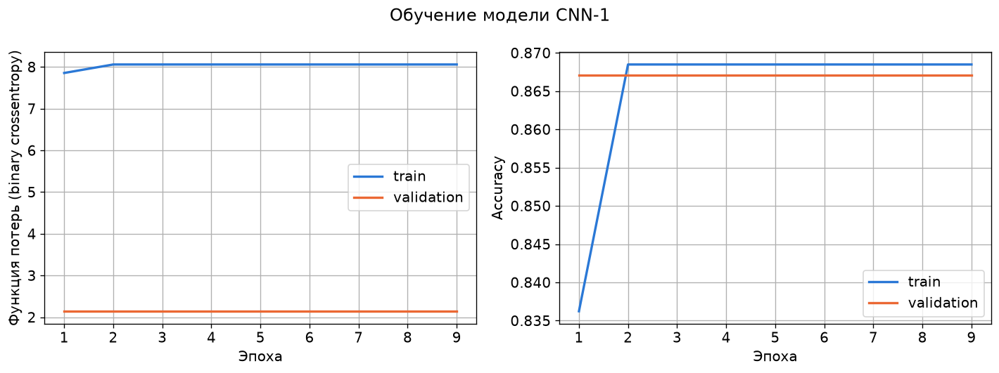

,Модель,Архитектура,Dropout,Аугментация,Оптимизатор,lr,Дисбаланс,Параметров,Макс. эпох,Эпох до остановки,Лучшая эпоха,"Время, с",train loss,val loss,train accuracy,val accuracy,val Balanced Accuracy,val Precision,val Recall,val ROC-AUC
0,CNN-1,"2 блока Conv 32-64, Flatten, Dense 128",0.0,нет,adam,0.001,class_weight,25709761,50,9,1,19.6,7.8554,2.1429,0.8362,0.8671,0.5,0.0,0.0,0.49


In [16]:
run_experiment("CNN-1", BASE_CONFIG, show_architecture=True)
plot_history("CNN-1", "binary-cnn-1-history.png")
short_table(["CNN-1"])

**Результат:** CNN-1 (25 709 761 параметр, 99,9% из них в слое Dense после Flatten) с шагом 0,001 не обучилась. Уже после первой эпохи loss на train застыл на 8,059, val loss на 2,1429, и сеть называет все снимки фитофторозом: Balanced Accuracy 0,5, ROC-AUC 0,49, как у `Dummy`. Early Stopping остановил обучение через 8 эпох без улучшения.

### CNN-1 с уменьшенной скоростью обучения

У CNN-1 первый полносвязный слой получает 56 x 56 x 64 = 200 704 входа, и в нём 25,7 млн весов. При шаге Adam 0,001 первые обновления этих весов слишком велики: выход сети уходит в насыщение sigmoid, градиент становится почти нулевым, и сеть застревает в ответе "фитофтороз" для всех снимков. Задание разрешает обосновать и изменить начальную скорость обучения, поэтому для CNN-1 уменьшаем её в 10 раз, до 0,0001. Дальше в сравнениях участвует эта версия, `CNN-1-lr0.0001`.

CNN-1-lr0.0001: эпох 42, лучшая 34, 95 с, val loss 0.0435, {'Accuracy': 0.9711, 'Balanced Accuracy': 0.9281, 'Precision': 0.9091, 'Recall': 0.8696, 'F1': 0.8889, 'Macro F1': 0.9361, 'ROC-AUC': 0.9974}


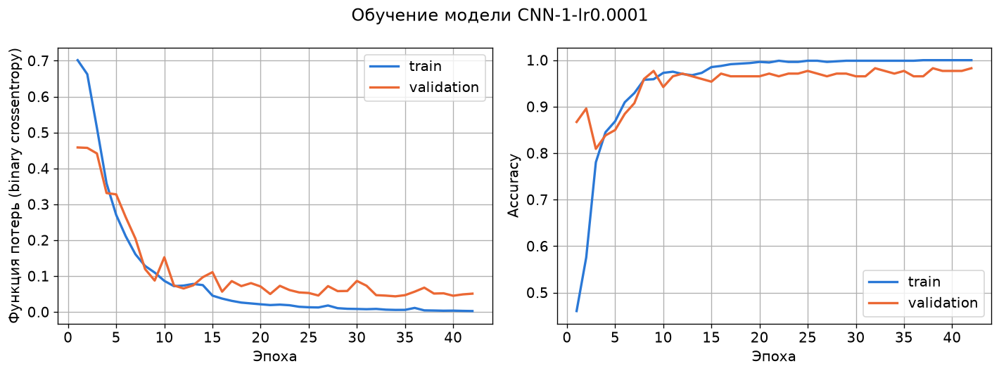

,Модель,Архитектура,Dropout,Аугментация,Оптимизатор,lr,Дисбаланс,Параметров,Макс. эпох,Эпох до остановки,Лучшая эпоха,"Время, с",train loss,val loss,train accuracy,val accuracy,val Balanced Accuracy,val Precision,val Recall,val ROC-AUC
0,CNN-1,"2 блока Conv 32-64, Flatten, Dense 128",0.0,нет,adam,0.0010,class_weight,25709761,50,9,1,19.6,7.8554,2.1429,0.8362,0.8671,0.5000,0.0000,0.0000,0.4900
1,CNN-1-lr0.0001,"2 блока Conv 32-64, Flatten, Dense 128",0.0,нет,adam,0.0001,class_weight,25709761,50,42,34,94.9,0.0057,0.0435,0.9988,0.9711,0.9281,0.9091,0.8696,0.9974


In [17]:
CNN1_CONFIG = {**BASE_CONFIG, "learning_rate": 0.0001}
run_experiment("CNN-1-lr0.0001", CNN1_CONFIG)
plot_history("CNN-1-lr0.0001", "binary-cnn-1-lr0.0001-history.png")
short_table(["CNN-1", "CNN-1-lr0.0001"])

**Результат:** с шагом 0,0001 CNN-1 обучается: лучшая эпоха 34 из 42, val loss 0,0435, Balanced Accuracy 0,9281, ROC-AUC 0,9974. При этом train loss 0,0057 и train accuracy 0,9988: сеть почти полностью запоминает обучающие снимки, val loss в 7,6 раза выше train loss. Огромный полносвязный слой даёт сети возможность заучивать снимки, это видно и по графику.

### 1. CNN-2: глубина сети, число фильтров и GlobalAveragePooling

Три свёрточных блока (32, 64, 128 фильтров), затем GlobalAveragePooling2D и Dense 128. Глубже сеть - больше поле зрения последних фильтров, и они видят пятно целиком. GlobalAveragePooling усредняет каждую карту признаков в одно число, поэтому параметров в полносвязной части в сотни раз меньше, чем с Flatten.

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,889 (429.25 KB)

 Trainable params: 109,889 (429.25 KB)

 Non-trainable params: 0 (0.00 B)

Активации по слоям: conv2d_4: relu, conv2d_5: relu, conv2d_6: relu, dense_4: relu, dense_5: sigmoid


CNN-2: эпох 25, лучшая 17, 44 с, val loss 0.0809, {'Accuracy': 0.9711, 'Balanced Accuracy': 0.9097, 'Precision': 0.95, 'Recall': 0.8261, 'F1': 0.8837, 'Macro F1': 0.9336, 'ROC-AUC': 0.9945}


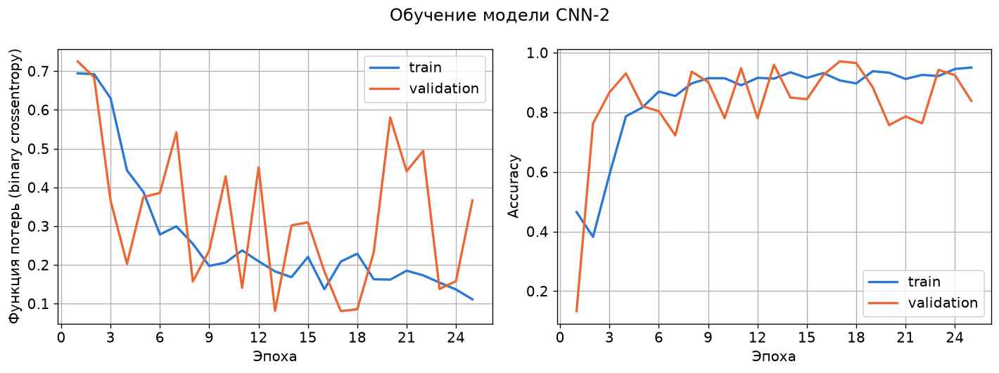

,Модель,Архитектура,Dropout,Аугментация,Оптимизатор,lr,Дисбаланс,Параметров,Макс. эпох,Эпох до остановки,Лучшая эпоха,"Время, с",train loss,val loss,train accuracy,val accuracy,val Balanced Accuracy,val Precision,val Recall,val ROC-AUC
0,CNN-1-lr0.0001,"2 блока Conv 32-64, Flatten, Dense 128",0.0,нет,adam,0.0001,class_weight,25709761,50,42,34,94.9,0.0057,0.0435,0.9988,0.9711,0.9281,0.9091,0.8696,0.9974
1,CNN-2,"3 блока Conv 32-64-128, GAP, Dense 128",0.0,нет,adam,0.0010,class_weight,109889,50,25,17,44.4,0.2087,0.0809,0.9069,0.9711,0.9097,0.9500,0.8261,0.9945


In [18]:
CNN2_CONFIG = {**BASE_CONFIG, "filters": (32, 64, 128), "pooling": "gap"}
run_experiment("CNN-2", CNN2_CONFIG, show_architecture=True)
plot_history("CNN-2", "binary-cnn-2-history.png")
short_table(["CNN-1-lr0.0001", "CNN-2"])

**Результат:** CNN-2 (109 889 параметров, в 234 раза меньше CNN-1) с шагом 0,001: лучшая эпоха 17 из 25, val loss 0,0809, Balanced Accuracy 0,9097, ROC-AUC 0,9945. Val loss хуже, чем у CNN-1-lr0.0001 (0,0435), на 0,037, а это больше допуска. Train loss 0,2087 выше val loss: train loss считается с весами классов и усредняется по эпохе, пока веса ещё меняются, поэтому его нельзя прямо сравнивать с val loss. Переобучения у CNN-2 нет: кривые train и validation идут рядом.

### 2. Число фильтров и глубина отдельно

В CNN-2 глубина и число фильтров изменились одновременно. Чтобы разделить их влияние, меняем по одному параметру:

- `CNN-2-narrow` - та же глубина 3 блока, но вдвое меньше фильтров (16, 32, 64);
- `CNN-2-deep` - на один блок глубже (32, 64, 128, 256), число фильтров в первых блоках то же.

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_7 (Conv2D)               │ (None, 224, 224, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 112, 112, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 112, 112, 32)   │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 56, 56, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 56, 56, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 28, 28, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 32,033 (125.13 KB)

 Trainable params: 32,033 (125.13 KB)

 Non-trainable params: 0 (0.00 B)

Активации по слоям: conv2d_7: relu, conv2d_8: relu, conv2d_9: relu, dense_6: relu, dense_7: sigmoid


... (4 outputs left out)

 Trainable params: 421,441 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

Активации по слоям: conv2d_10: relu, conv2d_11: relu, conv2d_12: relu, conv2d_13: relu, dense_8: relu, dense_9: sigmoid


CNN-2-deep: эпох 26, лучшая 18, 51 с, val loss 0.0669, {'Accuracy': 0.9711, 'Balanced Accuracy': 0.9465, 'Precision': 0.875, 'Recall': 0.913, 'F1': 0.8936, 'Macro F1': 0.9384, 'ROC-AUC': 0.9948}


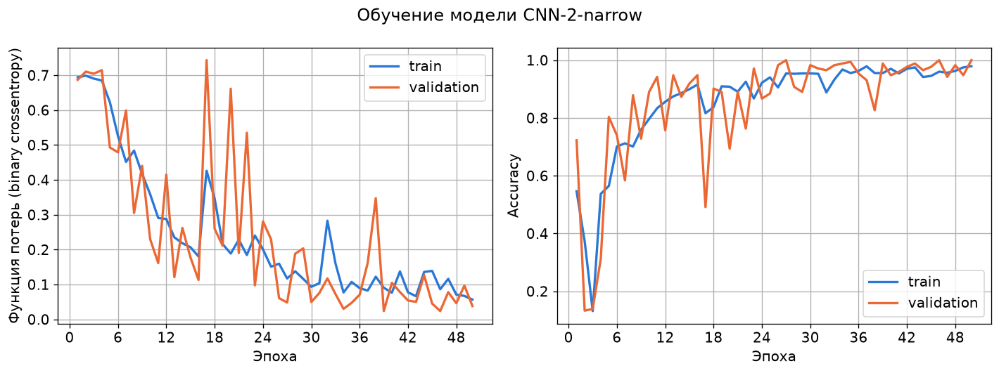

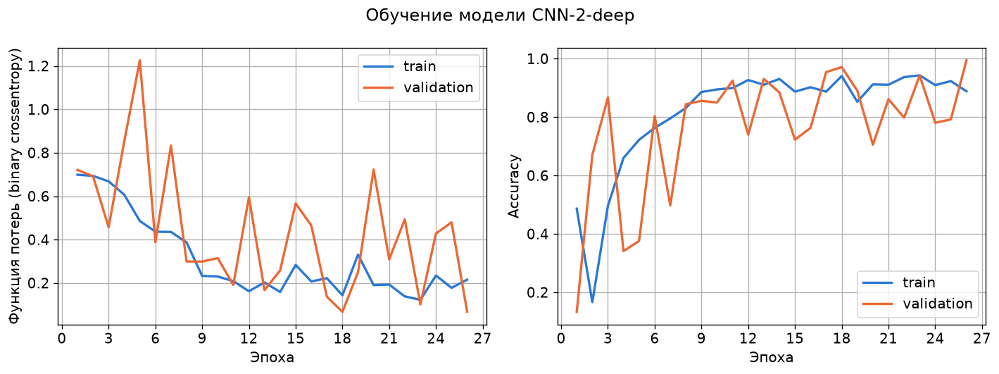

,Модель,Архитектура,Dropout,Аугментация,Оптимизатор,lr,Дисбаланс,Параметров,Макс. эпох,Эпох до остановки,Лучшая эпоха,"Время, с",train loss,val loss,train accuracy,val accuracy,val Balanced Accuracy,val Precision,val Recall,val ROC-AUC
0,CNN-1-lr0.0001,"2 блока Conv 32-64, Flatten, Dense 128",0.0,нет,adam,0.0001,class_weight,25709761,50,42,34,94.9,0.0057,0.0435,0.9988,0.9711,0.9281,0.9091,0.8696,0.9974
1,CNN-2,"3 блока Conv 32-64-128, GAP, Dense 128",0.0,нет,adam,0.0010,class_weight,109889,50,25,17,44.4,0.2087,0.0809,0.9069,0.9711,0.9097,0.9500,0.8261,0.9945
2,CNN-2-narrow,"3 блока Conv 16-32-64, GAP, Dense 128",0.0,нет,adam,0.0010,class_weight,32033,50,50,46,60.4,0.0865,0.0239,0.9603,1.0000,1.0000,1.0000,1.0000,1.0000
3,CNN-2-deep,"4 блока Conv 32-64-128-256, GAP, Dense 128",0.0,нет,adam,0.0010,class_weight,421441,50,26,18,50.8,0.1434,0.0669,0.9404,0.9711,0.9465,0.8750,0.9130,0.9948


In [19]:
run_experiment("CNN-2-narrow", {**CNN2_CONFIG, "filters": (16, 32, 64)}, show_architecture=True)
run_experiment("CNN-2-deep", {**CNN2_CONFIG, "filters": (32, 64, 128, 256)}, show_architecture=True)
plot_history("CNN-2-narrow", "binary-cnn-2-narrow-history.png")
plot_history("CNN-2-deep", "binary-cnn-2-deep-history.png")
short_table(["CNN-1-lr0.0001", "CNN-2", "CNN-2-narrow", "CNN-2-deep"])

**Результат:** `CNN-2-narrow` (16-32-64 фильтра, 32 033 параметра) дала лучший val loss 0,0239 и без ошибок на validation (Balanced Accuracy 1,0). `CNN-2-deep` (4 блока, 421 441 параметр): val loss 0,0669, лучше CNN-2 (0,0809) на 0,014. Больше фильтров и глубже не значит лучше: на 806 обучающих снимках с однородным фоном узкой сети хватает, а большие сети учатся дольше и сильнее колеблются. Узкая сеть обучалась все 50 эпох (лучшая 46): val loss ещё медленно снижался.

### 3. Разброс между запусками

Результат обучения зависит от случайных начальных весов и порядка батчей. Повторяем CNN-2 с двумя другими seed. Разница val loss между запусками одной и той же сети - это шум, и меньшие различия между архитектурами нельзя считать улучшением. Так проверяется допуск `LOSS_TOLERANCE`.

In [20]:
seed_names = ["CNN-2", "CNN-2-seed43", "CNN-2-seed44"]
run_experiment("CNN-2-seed43", CNN2_CONFIG, seed=SEED + 1)
run_experiment("CNN-2-seed44", CNN2_CONFIG, seed=SEED + 2)

seed_table = short_table(seed_names)
loss_spread = seed_table["val loss"].max() - seed_table["val loss"].min()
print(f"Разброс val loss между тремя запусками CNN-2: {loss_spread:.4f}, допуск LOSS_TOLERANCE = {LOSS_TOLERANCE}")
print("Разброс val Balanced Accuracy:", round(seed_table["val Balanced Accuracy"].max() - seed_table["val Balanced Accuracy"].min(), 4))
seed_table

CNN-2-seed43: эпох 23, лучшая 15, 42 с, val loss 0.0779, {'Accuracy': 0.9711, 'Balanced Accuracy': 0.9833, 'Precision': 0.8214, 'Recall': 1.0, 'F1': 0.902, 'Macro F1': 0.9425, 'ROC-AUC': 0.9977}


CNN-2-seed44: эпох 22, лучшая 14, 39 с, val loss 0.0740, {'Accuracy': 0.9711, 'Balanced Accuracy': 0.9281, 'Precision': 0.9091, 'Recall': 0.8696, 'F1': 0.8889, 'Macro F1': 0.9361, 'ROC-AUC': 0.9945}
Разброс val loss между тремя запусками CNN-2: 0.0069, допуск LOSS_TOLERANCE = 0.01
Разброс val Balanced Accuracy: 0.0736


,Модель,Архитектура,Dropout,Аугментация,Оптимизатор,lr,Дисбаланс,Параметров,Макс. эпох,Эпох до остановки,Лучшая эпоха,"Время, с",train loss,val loss,train accuracy,val accuracy,val Balanced Accuracy,val Precision,val Recall,val ROC-AUC
0,CNN-2,"3 блока Conv 32-64-128, GAP, Dense 128",0.0,нет,adam,0.001,class_weight,109889,50,25,17,44.4,0.2087,0.0809,0.9069,0.9711,0.9097,0.9500,0.8261,0.9945
1,CNN-2-seed43,"3 блока Conv 32-64-128, GAP, Dense 128",0.0,нет,adam,0.001,class_weight,109889,50,23,15,42.4,0.1735,0.0779,0.9256,0.9711,0.9833,0.8214,1.0000,0.9977
2,CNN-2-seed44,"3 блока Conv 32-64-128, GAP, Dense 128",0.0,нет,adam,0.001,class_weight,109889,50,22,14,39.0,0.2094,0.0740,0.8933,0.9711,0.9281,0.9091,0.8696,0.9945


**Результат:** три запуска CNN-2 с seed 42, 43, 44: val loss 0,0809, 0,0779, 0,0740, разброс 0,0069 - меньше допуска 0,01, допуск выбран правильно. Balanced Accuracy при этом меняется на 0,0736: на 23 здоровых снимках validation одна ошибка меняет Recall на 0,043, поэтому сравнивать модели по Accuracy или Balanced Accuracy ненадёжно, а val loss устойчивее. По той же причине повторный запуск всего ноутбука даёт немного другие числа.

Выбираем архитектуру по val loss с допуском. Дальше все эксперименты меняют параметры выбранной архитектуры.

In [21]:
architecture_names = ["CNN-2-narrow", "CNN-2", "CNN-2-deep", "CNN-1-lr0.0001"]
current_name = select_best(architecture_names)
current_config = dict(model_configs[current_name])
print("Выбрана архитектура:", current_name)
short_table(architecture_names).sort_values("val loss")

Выбрана архитектура: CNN-2-narrow


,Модель,Архитектура,Dropout,Аугментация,Оптимизатор,lr,Дисбаланс,Параметров,Макс. эпох,Эпох до остановки,Лучшая эпоха,"Время, с",train loss,val loss,train accuracy,val accuracy,val Balanced Accuracy,val Precision,val Recall,val ROC-AUC
0,CNN-2-narrow,"3 блока Conv 16-32-64, GAP, Dense 128",0.0,нет,adam,0.0010,class_weight,32033,50,50,46,60.4,0.0865,0.0239,0.9603,1.0000,1.0000,1.0000,1.0000,1.0000
3,CNN-1-lr0.0001,"2 блока Conv 32-64, Flatten, Dense 128",0.0,нет,adam,0.0001,class_weight,25709761,50,42,34,94.9,0.0057,0.0435,0.9988,0.9711,0.9281,0.9091,0.8696,0.9974
2,CNN-2-deep,"4 блока Conv 32-64-128-256, GAP, Dense 128",0.0,нет,adam,0.0010,class_weight,421441,50,26,18,50.8,0.1434,0.0669,0.9404,0.9711,0.9465,0.8750,0.9130,0.9948
1,CNN-2,"3 блока Conv 32-64-128, GAP, Dense 128",0.0,нет,adam,0.0010,class_weight,109889,50,25,17,44.4,0.2087,0.0809,0.9069,0.9711,0.9097,0.9500,0.8261,0.9945


**Результат:** выбрана `CNN-2-narrow`: у неё наименьший val loss 0,0239, следующая CNN-1-lr0.0001 (0,0435) хуже на 0,0196, это вдвое больше допуска. Она же самая простая, 32 033 параметра.

### 4. Оптимизатор и скорость обучения

Сравниваем на выбранной архитектуре:

- Adam 0,001 - текущая настройка;
- Adam 0,0001 - проверяем, не слишком ли велик шаг 0,001;
- RMSprop 0,001 - другой адаптивный метод;
- SGD с моментом 0,9 и шагом 0,01: у SGD нет адаптивного масштаба шага, поэтому с 0,001 он учится слишком медленно для 50 эпох.

CNN-2-narrow-adam-lr0.0001: эпох 50, лучшая 47, 61 с, val loss 0.1076, {'Accuracy': 0.9711, 'Balanced Accuracy': 0.9833, 'Precision': 0.8214, 'Recall': 1.0, 'F1': 0.902, 'Macro F1': 0.9425, 'ROC-AUC': 0.9983}


CNN-2-narrow-rmsprop: эпох 47, лучшая 39, 53 с, val loss 0.0439, {'Accuracy': 0.9827, 'Balanced Accuracy': 0.9348, 'Precision': 1.0, 'Recall': 0.8696, 'F1': 0.9302, 'Macro F1': 0.9602, 'ROC-AUC': 0.9988}


CNN-2-narrow-sgd: эпох 50, лучшая 44, 55 с, val loss 0.1029, {'Accuracy': 0.9711, 'Balanced Accuracy': 0.9097, 'Precision': 0.95, 'Recall': 0.8261, 'F1': 0.8837, 'Macro F1': 0.9336, 'ROC-AUC': 0.9849}


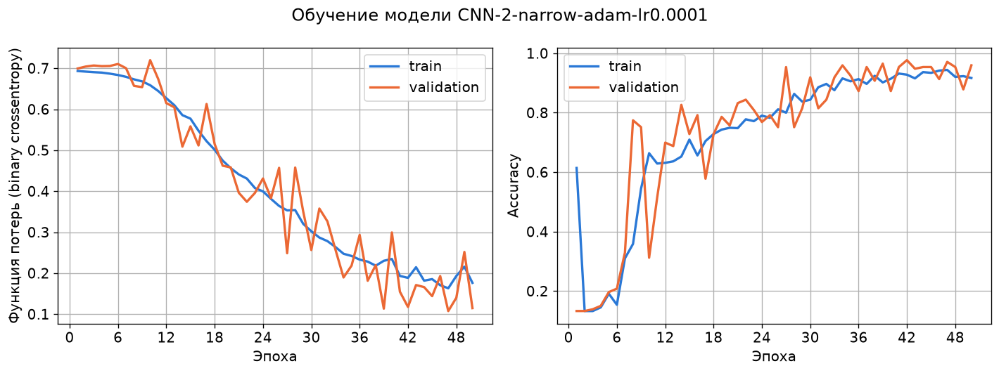

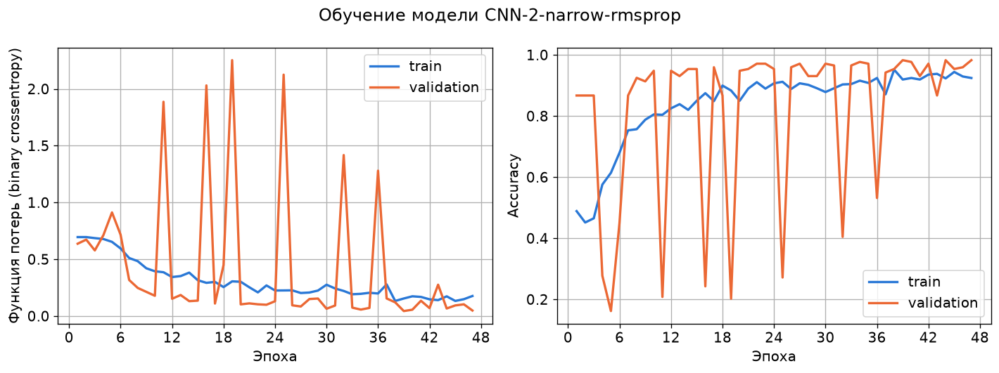

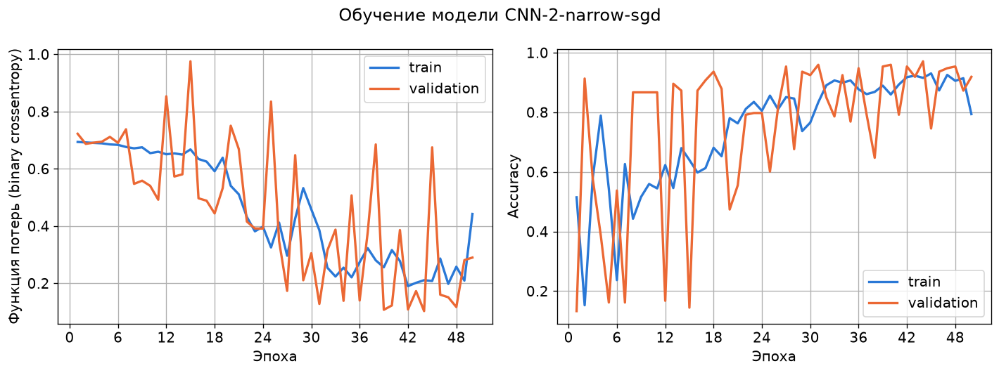

Выбрано: CNN-2-narrow


,Модель,Архитектура,Dropout,Аугментация,Оптимизатор,lr,Дисбаланс,Параметров,Макс. эпох,Эпох до остановки,Лучшая эпоха,"Время, с",train loss,val loss,train accuracy,val accuracy,val Balanced Accuracy,val Precision,val Recall,val ROC-AUC
0,CNN-2-narrow,"3 блока Conv 16-32-64, GAP, Dense 128",0.0,нет,adam,0.0010,class_weight,32033,50,50,46,60.4,0.0865,0.0239,0.9603,1.0000,1.0000,1.0000,1.0000,1.0000
1,CNN-2-narrow-adam-lr0.0001,"3 блока Conv 16-32-64, GAP, Dense 128",0.0,нет,adam,0.0001,class_weight,32033,50,50,47,61.4,0.1632,0.1076,0.9442,0.9711,0.9833,0.8214,1.0000,0.9983
2,CNN-2-narrow-rmsprop,"3 блока Conv 16-32-64, GAP, Dense 128",0.0,нет,rmsprop,0.0010,class_weight,32033,50,47,39,53.2,0.1545,0.0439,0.9194,0.9827,0.9348,1.0000,0.8696,0.9988
3,CNN-2-narrow-sgd,"3 блока Conv 16-32-64, GAP, Dense 128",0.0,нет,sgd,0.0100,class_weight,32033,50,50,44,55.5,0.2110,0.1029,0.9156,0.9711,0.9097,0.9500,0.8261,0.9849


In [22]:
optimizer_variants = {
    f"{current_name}-adam-lr0.0001": {"optimizer": "adam", "learning_rate": 0.0001},
    f"{current_name}-rmsprop": {"optimizer": "rmsprop", "learning_rate": 0.001},
    f"{current_name}-sgd": {"optimizer": "sgd", "learning_rate": 0.01},
}
for variant_name, changes in optimizer_variants.items():
    run_experiment(variant_name, {**current_config, **changes})

optimizer_names = [current_name] + list(optimizer_variants)
for variant_name in optimizer_variants:
    plot_history(variant_name, f"binary-{variant_name.lower()}-history.png")
current_name = select_best(optimizer_names)
current_config = dict(model_configs[current_name])
print("Выбрано:", current_name)
short_table(optimizer_names)

**Результат:** Adam 0,001 остаётся лучшим: val loss 0,0239. RMSprop 0,001 даёт 0,0439, SGD с моментом 0,9 и шагом 0,01 даёт 0,1029, Adam 0,0001 даёт 0,1076. С шагом 0,0001 и у SGD обучение за 50 эпох не закончилось (лучшие эпохи 47 и 44, val loss ещё падал). Шаг 0,001 подтверждён: он достаточно мал, чтобы узкая сеть не расходилась, и достаточно велик, чтобы она сошлась за 50 эпох. Для огромной CNN-1 он был слишком велик, для узкой сети с GlobalAveragePooling подходит.

### 5. Переобучение, Early Stopping и Dropout на CNN-1

CNN-1 с Flatten имеет больше всего параметров, поэтому на ней переобучение видно лучше всего. Берём рабочую версию с шагом 0,0001. Сначала обучаем её 40 эпох без Early Stopping: если val loss растёт, пока train loss падает, сеть запоминает обучающие снимки. Затем добавляем Dropout 0,3 после Dense 128 (конфигурация CNN-1 из таблицы задания) и сравниваем до и после.

CNN-1-no-es: эпох 40, лучшая 40, 102 с, val loss 0.0466, {'Accuracy': 0.9769, 'Balanced Accuracy': 0.9499, 'Precision': 0.913, 'Recall': 0.913, 'F1': 0.913, 'Macro F1': 0.9499, 'ROC-AUC': 0.9965}


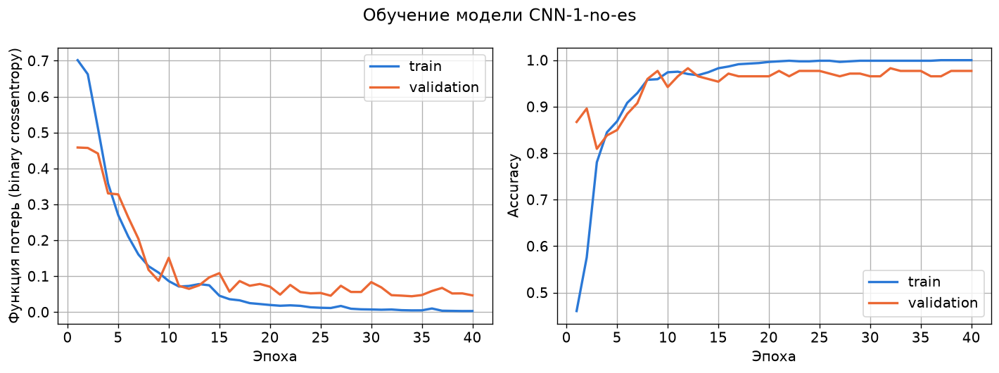

Model: "sequential_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_31 (Conv2D)              │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_31 (MaxPooling2D) │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_32 (Conv2D)              │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_32 (MaxPooling2D) │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 200704)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 128)            │    25,690,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,709,761 (98.07 MB)

 Trainable params: 25,709,761 (98.07 MB)

 Non-trainable params: 0 (0.00 B)

Активации по слоям: conv2d_31: relu, conv2d_32: relu, dense_22: relu, dense_23: sigmoid


CNN-1-dropout: эпох 29, лучшая 21, 62 с, val loss 0.0425, {'Accuracy': 0.9769, 'Balanced Accuracy': 0.9314, 'Precision': 0.9524, 'Recall': 0.8696, 'F1': 0.9091, 'Macro F1': 0.9479, 'ROC-AUC': 0.9983}


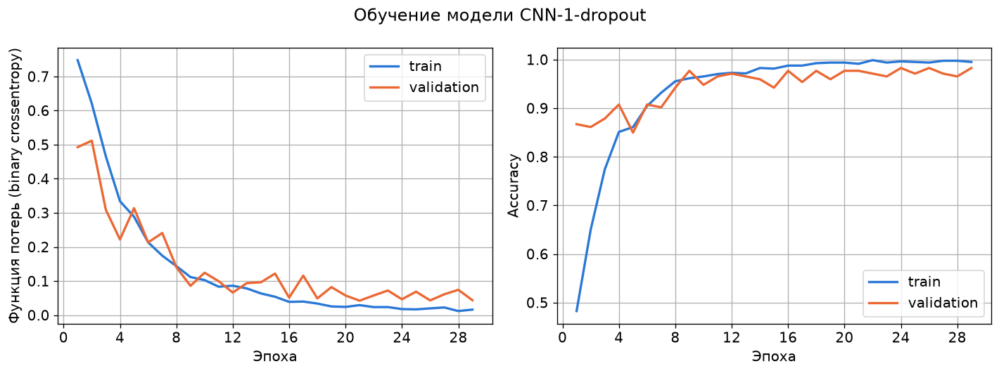

,Модель,Архитектура,Dropout,Аугментация,Оптимизатор,lr,Дисбаланс,Параметров,Макс. эпох,Эпох до остановки,Лучшая эпоха,"Время, с",train loss,val loss,train accuracy,val accuracy,val Balanced Accuracy,val Precision,val Recall,val ROC-AUC
0,CNN-1-lr0.0001,"2 блока Conv 32-64, Flatten, Dense 128",0.0,нет,adam,0.0001,class_weight,25709761,50,42,34,94.9,0.0057,0.0435,0.9988,0.9711,0.9281,0.9091,0.8696,0.9974
1,CNN-1-no-es,"2 блока Conv 32-64, Flatten, Dense 128",0.0,нет,adam,0.0001,class_weight,25709761,40,40,40,101.5,0.0030,0.0466,1.0000,0.9769,0.9499,0.9130,0.9130,0.9965
2,CNN-1-dropout,"2 блока Conv 32-64, Flatten, Dense 128",0.3,нет,adam,0.0001,class_weight,25709761,50,29,21,61.9,0.0294,0.0425,0.9913,0.9769,0.9314,0.9524,0.8696,0.9983


In [23]:
run_experiment("CNN-1-no-es", CNN1_CONFIG, max_epochs=40, use_early_stopping=False)
plot_history("CNN-1-no-es", "binary-cnn-1-no-es-history.png")

run_experiment("CNN-1-dropout", {**CNN1_CONFIG, "dropout": 0.3}, show_architecture=True)
plot_history("CNN-1-dropout", "binary-cnn-1-dropout-history.png")
short_table(["CNN-1-lr0.0001", "CNN-1-no-es", "CNN-1-dropout"])

**Результат:** без Early Stopping CNN-1 за 40 эпох полностью запомнила обучающую выборку: train accuracy 1,0, train loss 0,0030, а val loss 0,0466, в 15 раз выше. Это переобучение в виде разрыва между train и validation. Val loss при этом не растёт резко, а колеблется (0,0708 на 20-й эпохе, 0,0834 на 30-й, минимум 0,0441 на 34-й, 0,0466 на 40-й), потому что снимки чистые и классы хорошо разделимы, и запоминание мало вредит. Early Stopping выбирает эпоху с минимальным val loss и экономит эпохи. Dropout 0,3 уменьшил разрыв (train loss 0,0294 вместо 0,0057) и дал val loss 0,0425 против 0,0435 без него, но разница 0,001 намного меньше допуска 0,01: на validation Dropout в CNN-1 заметно не помог.

### 6. CNN-3: Dropout 0,5 на выбранной сети

CNN-3 из таблицы задания: выбранная сеть с Dropout 0,5 после Dense 128. Проверяем, нужна ли регуляризация сети, у которой параметров немного.

Model: "sequential_12"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_33 (Conv2D)              │ (None, 224, 224, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_33 (MaxPooling2D) │ (None, 112, 112, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_34 (Conv2D)              │ (None, 112, 112, 32)   │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_34 (MaxPooling2D) │ (None, 56, 56, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_35 (Conv2D)              │ (None, 56, 56, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_35 (MaxPooling2D) │ (None, 28, 28, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_8      │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_24 (Dense)                │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_25 (Dense)                │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 32,033 (125.13 KB)

 Trainable params: 32,033 (125.13 KB)

 Non-trainable params: 0 (0.00 B)

Активации по слоям: conv2d_33: relu, conv2d_34: relu, conv2d_35: relu, dense_24: relu, dense_25: sigmoid


CNN-3: эпох 25, лучшая 17, 29 с, val loss 0.1190, {'Accuracy': 0.9422, 'Balanced Accuracy': 0.9667, 'Precision': 0.697, 'Recall': 1.0, 'F1': 0.8214, 'Macro F1': 0.8935, 'ROC-AUC': 0.9959}


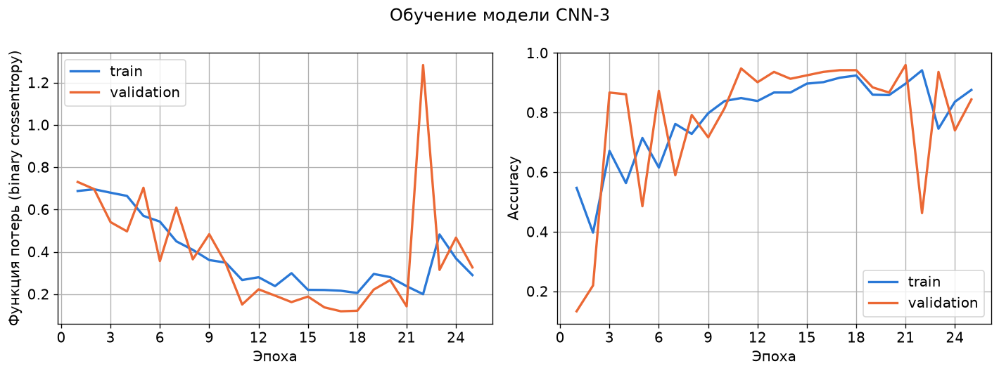

Выбрано: CNN-2-narrow


,Модель,Архитектура,Dropout,Аугментация,Оптимизатор,lr,Дисбаланс,Параметров,Макс. эпох,Эпох до остановки,Лучшая эпоха,"Время, с",train loss,val loss,train accuracy,val accuracy,val Balanced Accuracy,val Precision,val Recall,val ROC-AUC
0,CNN-2-narrow,"3 блока Conv 16-32-64, GAP, Dense 128",0.0,нет,adam,0.001,class_weight,32033,50,50,46,60.4,0.0865,0.0239,0.9603,1.0000,1.0000,1.000,1.0,1.0000
1,CNN-3,"3 блока Conv 16-32-64, GAP, Dense 128",0.5,нет,adam,0.001,class_weight,32033,50,25,17,28.7,0.2161,0.1190,0.9169,0.9422,0.9667,0.697,1.0,0.9959


In [24]:
# CNN-3 - выбранная сеть с Dropout 0,5
cnn3_name = "CNN-3"
run_experiment(cnn3_name, {**current_config, "dropout": 0.5}, show_architecture=True)
plot_history(cnn3_name, "binary-cnn-3-history.png")

regularization_names = [current_name, cnn3_name]
current_name = select_best(regularization_names)
current_config = dict(model_configs[current_name])
print("Выбрано:", current_name)
short_table(regularization_names)

**Результат:** CNN-3 (CNN-2-narrow + Dropout 0,5) хуже: val loss 0,1190 против 0,0239, Balanced Accuracy 0,9667 против 1,0, Precision здоровых 0,697 (10 больных листьев названы здоровыми). У сети всего 128 нейронов в Dense, и отключение половины из них мешает ей обучиться: это недообучение, о котором предупреждает задание. Переобучения у узкой сети не было, поэтому Dropout ей не нужен, остаётся CNN-2-narrow.

### 7. Учёт дисбаланса классов: с весами и без

Обучаем выбранную сеть без весов классов и сравниваем с обученной с весами на validation: метрики и матрицы ошибок до и после в одном месте.

CNN-2-narrow-no-weights: эпох 38, лучшая 30, 43 с, val loss 0.0238, {'Accuracy': 1.0, 'Balanced Accuracy': 1.0, 'Precision': 1.0, 'Recall': 1.0, 'F1': 1.0, 'Macro F1': 1.0, 'ROC-AUC': 1.0}


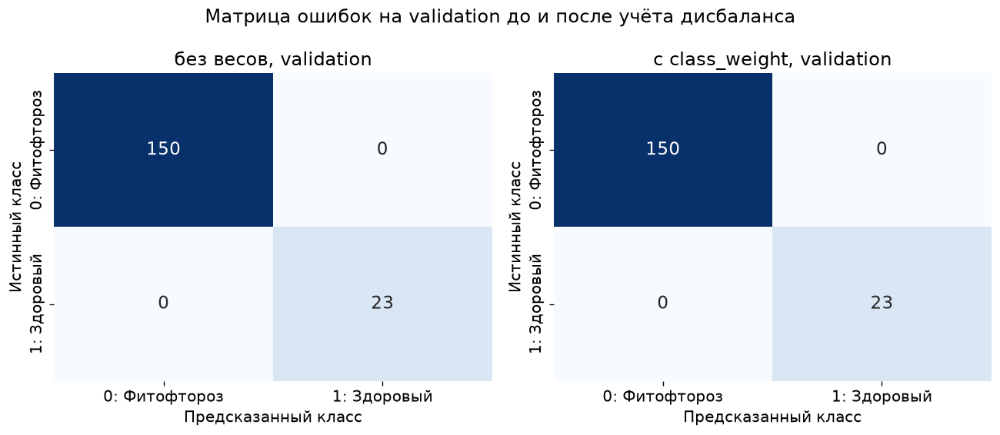

,Accuracy,Balanced Accuracy,Precision,Recall,F1,Macro F1,ROC-AUC,Больных названо здоровыми (FP),Здоровых названо больными (FN)
без весов,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0,0.0
с class_weight,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0,0.0


In [25]:
no_weights_name = f"{current_name}-no-weights"
run_experiment(no_weights_name, current_config, weighting="none")

figure, axes = plt.subplots(1, 2, figsize=(11, 4.8))
imbalance_rows = {}
for axis, (model_name, label) in zip(axes, [(no_weights_name, "без весов"), (current_name, "с class_weight")]):
    model = load_trained(model_name)
    probabilities = model.predict(X_val, batch_size=64, verbose=0).ravel()
    matrix = plot_confusion(y_val, (probabilities >= 0.5).astype(int), f"{label}, validation", None, axis=axis)
    imbalance_rows[label] = {**evaluate_binary(y_val, probabilities),
                             "Больных названо здоровыми (FP)": int(matrix[0, 1]),
                             "Здоровых названо больными (FN)": int(matrix[1, 0])}
    del model
figure.suptitle("Матрица ошибок на validation до и после учёта дисбаланса")
figure.tight_layout()
figure.savefig(FIGURES_DIR / "binary-imbalance-confusion.png")
plt.show()

imbalance_table = pd.DataFrame(imbalance_rows).T
imbalance_table.to_csv(RESULTS_DIR / "binary-imbalance-comparison.csv", encoding="utf-8")
imbalance_table

**Результат:** на validation обе версии не ошибаются ни разу: Balanced Accuracy 1,0, ни одного больного листа не названо здоровым и ни одного здорового больным. Val loss тоже почти равен: 0,0238 без весов и 0,0239 с весами. Классы на этих снимках разделяются настолько хорошо, что дисбаланс 6,6 : 1 не мешает сети найти редкий класс. Веса классов оставлены, потому что они не ухудшают validation и защищают от перекоса в сторону частого класса, но в этом наборе их эффект в пределах шума.

### 8. Аугментация обучающих данных

Слои аугментации ставятся в начало сети. Keras применяет их только при обучении (`fit`), а при `predict` и `evaluate` они пропускают снимок без изменений, поэтому validation и test не меняются. Преобразования: отражения по горизонтали и вертикали, поворот до 18 градусов, масштаб и сдвиг до 10%. Цвет и яркость не меняются, потому что цвет пятен и желтизна листа - признаки болезни.

Два варианта:

- `aug` - выбранная сеть с аугментацией и весами классов;
- `aug-oversample` - вместо весов классов здоровые листья повторяются в обучающей выборке, пока классов не станет поровну. Аугментация делает каждый повтор другим снимком, так редкий класс получает новые примеры, а не только больший вес.

С аугментацией каждая эпоха показывает сети новые варианты снимков, поэтому сеть сходится медленнее, а val loss сильнее колеблется. Пробный запуск с обычными 50 эпохами и patience 8 остановился на 21-й эпохе, когда val loss ещё прыгал от эпохи к эпохе. Поэтому для аугментированных сетей до 100 эпох и patience 15 (`AUG_MAX_EPOCHS`, `AUG_PATIENCE`); правило выбора лучшей эпохи по val loss то же.

Сначала посмотрим, как выглядят аугментированные снимки.

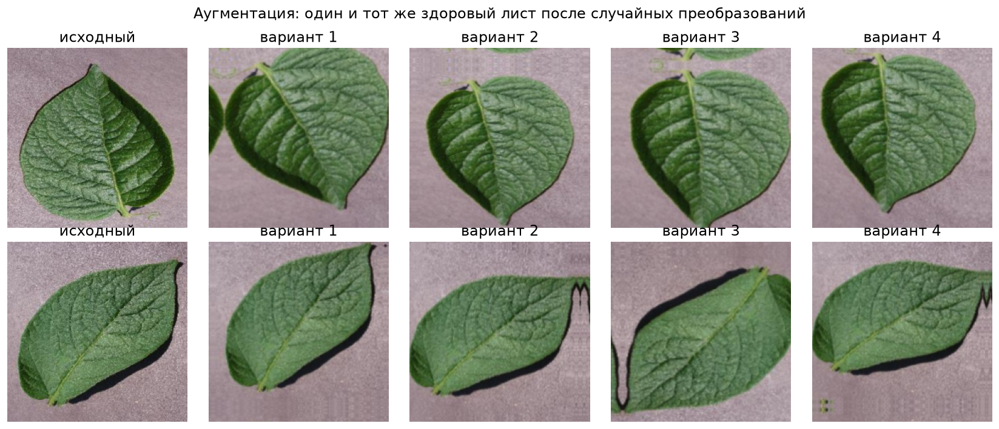

Снимки при инференсе не изменены: True


In [26]:
augmentation = build_augmentation()
example_images = X_train[np.flatnonzero(y_train == POSITIVE_LABEL)[:2]]
figure, axes = plt.subplots(2, 5, figsize=(14, 6))
for row, image in enumerate(example_images):
    axes[row, 0].imshow(image)
    axes[row, 0].set_title("исходный")
    for column in range(1, 5):
        augmented = keras.ops.convert_to_numpy(augmentation(image[None], training=True))[0]
        axes[row, column].imshow(np.clip(augmented, 0, 1))
        axes[row, column].set_title(f"вариант {column}")
for axis in axes.ravel():
    axis.axis("off")
figure.suptitle("Аугментация: один и тот же здоровый лист после случайных преобразований")
figure.tight_layout()
figure.savefig(FIGURES_DIR / "binary-augmentation-examples.png")
plt.show()

# Проверка: без training=True аугментация не меняет снимок
unchanged = keras.ops.convert_to_numpy(augmentation(example_images, training=False))
print("Снимки при инференсе не изменены:", bool(np.allclose(unchanged, example_images)))

Model: "sequential_16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_45 (Conv2D)              │ (None, 224, 224, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_45 (MaxPooling2D) │ (None, 112, 112, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_46 (Conv2D)              │ (None, 112, 112, 32)   │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_46 (MaxPooling2D) │ (None, 56, 56, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_47 (Conv2D)              │ (None, 56, 56, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_47 (MaxPooling2D) │ (None, 28, 28, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_12     │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_32 (Dense)                │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_33 (Dense)                │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 32,033 (125.13 KB)

 Trainable params: 32,033 (125.13 KB)

 Non-trainable params: 0 (0.00 B)

Активации по слоям: conv2d_45: relu, conv2d_46: relu, conv2d_47: relu, dense_32: relu, dense_33: sigmoid


CNN-2-narrow-aug: эпох 28, лучшая 13, 338 с, val loss 0.1628, {'Accuracy': 0.9422, 'Balanced Accuracy': 0.9299, 'Precision': 0.7241, 'Recall': 0.913, 'F1': 0.8077, 'Macro F1': 0.8868, 'ROC-AUC': 0.987}


CNN-2-narrow-aug-oversample: эпох 54, лучшая 39, 1124 с, val loss 0.1150, {'Accuracy': 0.948, 'Balanced Accuracy': 0.97, 'Precision': 0.7188, 'Recall': 1.0, 'F1': 0.8364, 'Macro F1': 0.9027, 'ROC-AUC': 1.0}


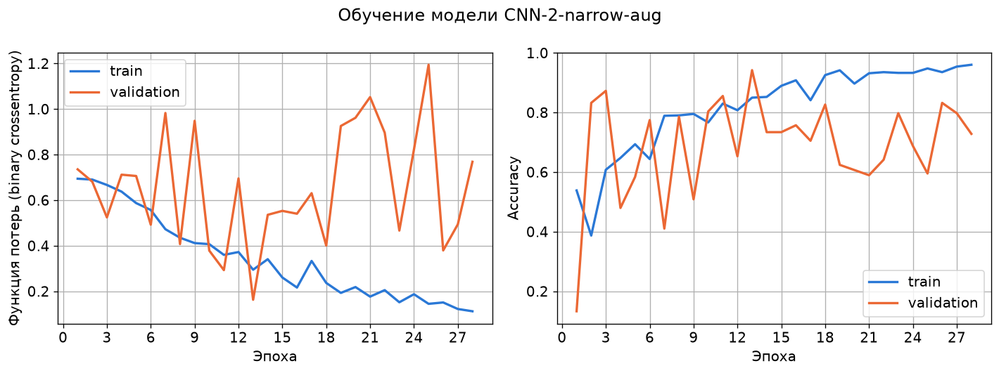

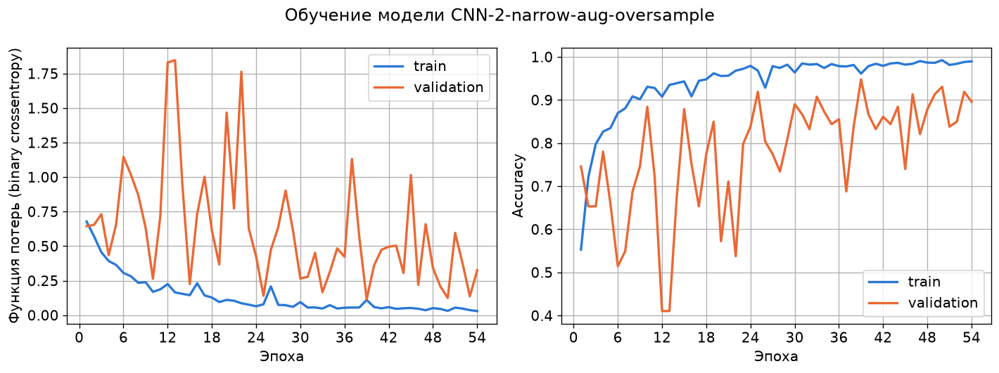

Выбрано: CNN-2-narrow


,Модель,Архитектура,Dropout,Аугментация,Оптимизатор,lr,Дисбаланс,Параметров,Макс. эпох,Эпох до остановки,...,train loss,val loss,train accuracy,val accuracy,val Balanced Accuracy,val Precision,val Recall,val ROC-AUC,разрыв loss (val - train),разрыв accuracy (train - val)
0,CNN-2-narrow,"3 блока Conv 16-32-64, GAP, Dense 128",0.0,нет,adam,0.001,class_weight,32033,50,50,...,0.0865,0.0239,0.9603,1.0000,1.0000,1.0000,1.000,1.000,-0.0626,-0.0397
1,CNN-2-narrow-aug,"3 блока Conv 16-32-64, GAP, Dense 128",0.0,да,adam,0.001,class_weight,32033,100,28,...,0.2948,0.1628,0.8499,0.9422,0.9299,0.7241,0.913,0.987,-0.1320,-0.0923
2,CNN-2-narrow-aug-oversample,"3 блока Conv 16-32-64, GAP, Dense 128",0.0,да,adam,0.001,повтор + аугментация,32033,100,54,...,0.1105,0.1150,0.9612,0.9480,0.9700,0.7188,1.000,1.000,0.0045,0.0132


In [27]:
before_augmentation_name = current_name
aug_name = f"{current_name}-aug"
aug_oversample_name = f"{current_name}-aug-oversample"
run_experiment(aug_name, {**current_config, "augment": True}, show_architecture=True,
               max_epochs=AUG_MAX_EPOCHS, patience=AUG_PATIENCE)
run_experiment(aug_oversample_name, {**current_config, "augment": True}, weighting="oversample",
               max_epochs=AUG_MAX_EPOCHS, patience=AUG_PATIENCE)
plot_history(aug_name, "binary-aug-history.png")
plot_history(aug_oversample_name, "binary-aug-oversample-history.png")

augmentation_names = [before_augmentation_name, aug_name, aug_oversample_name]
augmentation_table = short_table(augmentation_names)
# Разрыв между train и validation: насколько модель лучше на знакомых снимках
augmentation_table["разрыв loss (val - train)"] = (augmentation_table["val loss"] - augmentation_table["train loss"]).round(4)
augmentation_table["разрыв accuracy (train - val)"] = (augmentation_table["train accuracy"] - augmentation_table["val accuracy"]).round(4)

current_name = select_best(augmentation_names)
current_config = dict(model_configs[current_name])
print("Выбрано:", current_name)
augmentation_table

**Результат:** аугментация на validation не улучшила результат. `aug`: val loss 0,1628 (лучшая эпоха 13 из 28), Balanced Accuracy 0,9299. `aug-oversample`: val loss 0,1150 (эпоха 39 из 54), Balanced Accuracy 0,97, Recall здоровых 1,0, но Precision 0,7188. Без аугментации val loss 0,0239. Обучение с аугментацией в 5-19 раз дольше (338 и 1124 с против 60 с). Разрыв train/val у аугментированных моделей больше не показывает переобучения: train accuracy 0,8499 у `aug` ниже validation 0,9422, потому что сеть учится на более трудных, искажённых снимках. Причина: в validation и test все листья сняты одинаково (сверху, на сером фоне, по центру), и повороты, сдвиги и масштаб создают снимки, которых в проверочных данных нет. Обобщающая способность на этих данных не выросла, а переобучения, с которым должна бороться аугментация, у узкой сети и не было. Выбрана модель без аугментации.

### 9. Итоговая модель и порог классификации

Итоговая модель - результат последовательного выбора по validation. Порог 0,5 не обязан быть лучшим: веса классов сдвигают вероятности. Подбираем порог на validation, максимизируя Balanced Accuracy (одинаково важны оба класса); при равенстве берётся порог, ближайший к 0,5. Test в подборе не участвует.

Итоговая модель: CNN-2-narrow


Model: "sequential_18"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_51 (Conv2D)              │ (None, 224, 224, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_51 (MaxPooling2D) │ (None, 112, 112, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_52 (Conv2D)              │ (None, 112, 112, 32)   │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_52 (MaxPooling2D) │ (None, 56, 56, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_53 (Conv2D)              │ (None, 56, 56, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_53 (MaxPooling2D) │ (None, 28, 28, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_14     │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_36 (Dense)                │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_37 (Dense)                │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 32,033 (125.13 KB)

 Trainable params: 32,033 (125.13 KB)

 Non-trainable params: 0 (0.00 B)

Активации по слоям: conv2d_51: relu, conv2d_52: relu, conv2d_53: relu, dense_36: relu, dense_37: sigmoid


Выбранный порог: 0.5


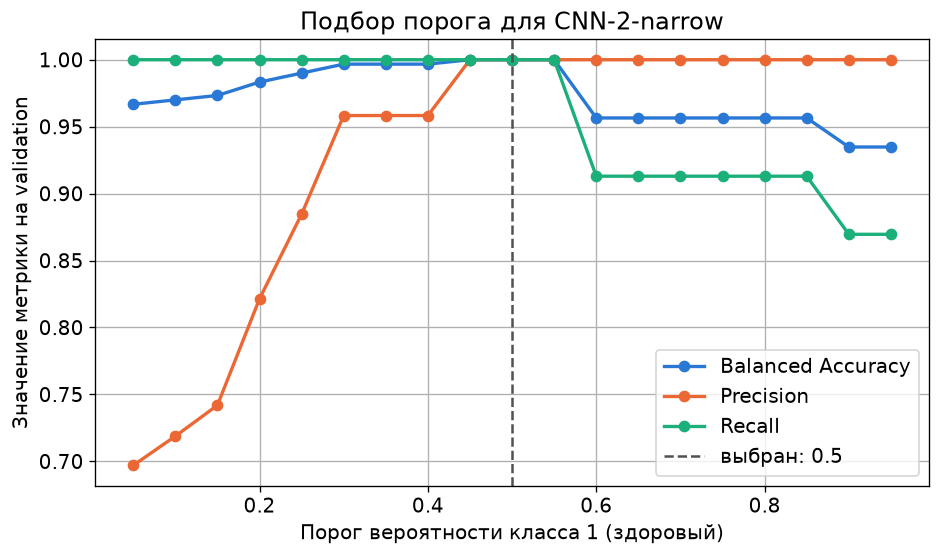

,Порог,Balanced Accuracy,Precision,Recall,F1
0,0.05,0.9667,0.6970,1.0000,0.8214
1,0.10,0.9700,0.7188,1.0000,0.8364
2,0.15,0.9733,0.7419,1.0000,0.8519
3,0.20,0.9833,0.8214,1.0000,0.9020
4,0.25,0.9900,0.8846,1.0000,0.9388
5,0.30,0.9967,0.9583,1.0000,0.9787
6,0.35,0.9967,0.9583,1.0000,0.9787
7,0.40,0.9967,0.9583,1.0000,0.9787
8,0.45,1.0000,1.0000,1.0000,1.0000
9,0.50,1.0000,1.0000,1.0000,1.0000


In [28]:
final_name = current_name
final_model = load_trained(final_name)
print("Итоговая модель:", final_name)
describe_architecture(final_model)

final_val_probabilities = final_model.predict(X_val, batch_size=64, verbose=0).ravel()
thresholds = np.round(np.arange(0.05, 0.96, 0.05), 2)
threshold_rows = []
for threshold in thresholds:
    metrics = evaluate_binary(y_val, final_val_probabilities, threshold)
    threshold_rows.append({"Порог": threshold, **{name: metrics[name] for name in
                                                  ["Balanced Accuracy", "Precision", "Recall", "F1"]}})
threshold_table = pd.DataFrame(threshold_rows)
threshold_table.to_csv(RESULTS_DIR / "binary-threshold.csv", index=False, encoding="utf-8")

best_ba = threshold_table["Balanced Accuracy"].max()
best_rows = threshold_table[threshold_table["Balanced Accuracy"] == best_ba]
FINAL_THRESHOLD = float(best_rows.loc[(best_rows["Порог"] - 0.5).abs().idxmin(), "Порог"])
print("Выбранный порог:", FINAL_THRESHOLD)

figure, axis = plt.subplots(figsize=(8, 4.8))
for metric, color in [("Balanced Accuracy", "#2a78d6"), ("Precision", "#eb6834"), ("Recall", "#1baf7a")]:
    axis.plot(threshold_table["Порог"], threshold_table[metric], marker="o", linewidth=2, color=color, label=metric)
axis.axvline(FINAL_THRESHOLD, color=TEST_COLOR, linestyle="--", label=f"выбран: {FINAL_THRESHOLD}")
axis.set_xlabel("Порог вероятности класса 1 (здоровый)")
axis.set_ylabel("Значение метрики на validation")
axis.set_title(f"Подбор порога для {final_name}")
axis.legend()
figure.tight_layout()
figure.savefig(FIGURES_DIR / "binary-threshold.png")
plt.show()
threshold_table

**Результат:** на validation пороги 0,45, 0,5 и 0,55 дают Balanced Accuracy 1,0. Из равных выбран ближайший к 0,5, то есть 0,5. Ниже 0,45 растёт число больных листьев, названных здоровыми (Precision падает до 0,697 при пороге 0,05), выше 0,55 модель начинает пропускать здоровые листья (Recall 0,913). Порог по умолчанию оказался оптимальным, потому что модель уверенно разделяет классы.

Сохраняем итоговую модель целиком (архитектура, веса, оптимизатор) и полную таблицу экспериментов с параметрами.

In [29]:
final_model.save(MODELS_DIR / "binary-best.keras")
pd.Series({"model": final_name, "threshold": FINAL_THRESHOLD, "positive_label": POSITIVE_LABEL,
           "input": f"{IMAGE_SIZE}x{IMAGE_SIZE}x3 RGB, pixels / 255"}).to_csv(
    RESULTS_DIR / "binary-best-model.csv", header=["value"], encoding="utf-8")

all_experiments = experiments_table()
all_experiments.to_csv(RESULTS_DIR / "binary-experiments.csv", index=False, encoding="utf-8")
pd.set_option("display.max_columns", None, "display.width", 250)
all_experiments

,Модель,Вход,Архитектура,Dropout,Аугментация,Оптимизатор,lr,Batch,Дисбаланс,Seed,Параметров,Макс. эпох,Patience,Эпох до остановки,Лучшая эпоха,"Время, с",train loss,val loss,train accuracy,val accuracy,val Balanced Accuracy,val Precision,val Recall,val F1,val Macro F1,val ROC-AUC
0,CNN-1,224x224x3,"2 блока Conv 32-64, Flatten, Dense 128",0.0,нет,adam,0.0010,32,class_weight,42,25709761,50,8,9,1,19.6,7.8554,2.1429,0.8362,0.8671,0.5000,0.0000,0.0000,0.0000,0.4644,0.4900
1,CNN-1-lr0.0001,224x224x3,"2 блока Conv 32-64, Flatten, Dense 128",0.0,нет,adam,0.0001,32,class_weight,42,25709761,50,8,42,34,94.9,0.0057,0.0435,0.9988,0.9711,0.9281,0.9091,0.8696,0.8889,0.9361,0.9974
2,CNN-2,224x224x3,"3 блока Conv 32-64-128, GAP, Dense 128",0.0,нет,adam,0.0010,32,class_weight,42,109889,50,8,25,17,44.4,0.2087,0.0809,0.9069,0.9711,0.9097,0.9500,0.8261,0.8837,0.9336,0.9945
3,CNN-2-narrow,224x224x3,"3 блока Conv 16-32-64, GAP, Dense 128",0.0,нет,adam,0.0010,32,class_weight,42,32033,50,8,50,46,60.4,0.0865,0.0239,0.9603,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
4,CNN-2-deep,224x224x3,"4 блока Conv 32-64-128-256, GAP, Dense 128",0.0,нет,adam,0.0010,32,class_weight,42,421441,50,8,26,18,50.8,0.1434,0.0669,0.9404,0.9711,0.9465,0.8750,0.9130,0.8936,0.9384,0.9948
5,CNN-2-seed43,224x224x3,"3 блока Conv 32-64-128, GAP, Dense 128",0.0,нет,adam,0.0010,32,class_weight,43,109889,50,8,23,15,42.4,0.1735,0.0779,0.9256,0.9711,0.9833,0.8214,1.0000,0.9020,0.9425,0.9977
6,CNN-2-seed44,224x224x3,"3 блока Conv 32-64-128, GAP, Dense 128",0.0,нет,adam,0.0010,32,class_weight,44,109889,50,8,22,14,39.0,0.2094,0.0740,0.8933,0.9711,0.9281,0.9091,0.8696,0.8889,0.9361,0.9945
7,CNN-2-narrow-adam-lr0.0001,224x224x3,"3 блока Conv 16-32-64, GAP, Dense 128",0.0,нет,adam,0.0001,32,class_weight,42,32033,50,8,50,47,61.4,0.1632,0.1076,0.9442,0.9711,0.9833,0.8214,1.0000,0.9020,0.9425,0.9983
8,CNN-2-narrow-rmsprop,224x224x3,"3 блока Conv 16-32-64, GAP, Dense 128",0.0,нет,rmsprop,0.0010,32,class_weight,42,32033,50,8,47,39,53.2,0.1545,0.0439,0.9194,0.9827,0.9348,1.0000,0.8696,0.9302,0.9602,0.9988
9,CNN-2-narrow-sgd,224x224x3,"3 блока Conv 16-32-64, GAP, Dense 128",0.0,нет,sgd,0.0100,32,class_weight,42,32033,50,8,50,44,55.5,0.2110,0.1029,0.9156,0.9711,0.9097,0.9500,0.8261,0.8837,0.9336,0.9849


## Итоговая оценка на тестовой выборке

Модель уже выбрана по validation, порог тоже. Тестовая выборка используется один раз: для итоговой модели и, как отчёт, для остальных моделей без каких-либо изменений после этого. Сравнение до и после аугментации - на одних и тех же тестовых снимках.

In [30]:
# Модели-иллюстрации без Early Stopping не участвуют в сравнении: это не кандидаты
report_names = [name for name in model_configs if not name.endswith("-no-es") and "-seed" not in name]

test_rows = [{"Модель": "Dummy", "Порог": 0.5,
              **evaluate_binary(y_test, dummy.predict_proba(np.zeros((len(y_test), 1)))[:, 1])}]
test_probabilities = {}
for model_name in report_names:
    model = load_trained(model_name)
    test_probabilities[model_name] = model.predict(X_test, batch_size=64, verbose=0).ravel()
    test_rows.append({"Модель": model_name, "Порог": 0.5, **evaluate_binary(y_test, test_probabilities[model_name])})
    del model
    gc.collect()
test_rows.append({"Модель": f"{final_name} (итоговая)", "Порог": FINAL_THRESHOLD,
                  **evaluate_binary(y_test, test_probabilities[final_name], FINAL_THRESHOLD)})

test_table = pd.DataFrame(test_rows)
test_table.to_csv(RESULTS_DIR / "binary-test-metrics.csv", index=False, encoding="utf-8")
test_table

,Модель,Порог,Accuracy,Balanced Accuracy,Precision,Recall,F1,Macro F1,ROC-AUC
0,Dummy,0.5,0.8671,0.5000,0.0000,0.0000,0.0000,0.4644,0.5000
1,CNN-1,0.5,0.8671,0.5000,0.0000,0.0000,0.0000,0.4644,0.4967
2,CNN-1-lr0.0001,0.5,0.9595,0.8846,0.9000,0.7826,0.8372,0.9071,0.9936
3,CNN-2,0.5,0.9595,0.8478,1.0000,0.6957,0.8205,0.8989,0.9788
4,CNN-2-narrow,0.5,0.9711,0.9097,0.9500,0.8261,0.8837,0.9336,0.9965
5,CNN-2-deep,0.5,0.9769,0.9130,1.0000,0.8261,0.9048,0.9458,0.9817
6,CNN-2-narrow-adam-lr0.0001,0.5,0.9653,0.9248,0.8696,0.8696,0.8696,0.9248,0.9913
7,CNN-2-narrow-rmsprop,0.5,0.9711,0.8913,1.0000,0.7826,0.8780,0.9308,0.9922
8,CNN-2-narrow-sgd,0.5,0.9769,0.9130,1.0000,0.8261,0.9048,0.9458,0.9794
9,CNN-1-dropout,0.5,0.9538,0.8629,0.8947,0.7391,0.8095,0.8916,0.9901


**Результат:** итоговая CNN-2-narrow на test: Accuracy 0,9711, Balanced Accuracy 0,9097, Precision 0,95, Recall 0,8261, F1 0,8837, ROC-AUC 0,9965. `Dummy`: Accuracy 0,8671, Balanced Accuracy 0,5, ROC-AUC 0,5. Ориентир 0,80 превышен по всем метрикам. На test несколько моделей немного лучше по Balanced Accuracy (например, без весов 0,9348, aug-oversample 0,9483), но разница - одна-две ошибки на 23 здоровых снимках, это в пределах шума, а выбор сделан по validation и не меняется. CNN-1 с шагом 0,001 на test так же беспомощна, как `Dummy`.

### До и после аугментации на тестовой выборке

In [31]:
augmentation_test = test_table.set_index("Модель").loc[augmentation_names].reset_index()
augmentation_test = augmentation_test.merge(
    augmentation_table[["Модель", "разрыв loss (val - train)", "разрыв accuracy (train - val)"]], on="Модель")
augmentation_test.to_csv(RESULTS_DIR / "binary-augmentation-test.csv", index=False, encoding="utf-8")
augmentation_test

,Модель,Порог,Accuracy,Balanced Accuracy,Precision,Recall,F1,Macro F1,ROC-AUC,разрыв loss (val - train),разрыв accuracy (train - val)
0,CNN-2-narrow,0.5,0.9711,0.9097,0.9500,0.8261,0.8837,0.9336,0.9965,-0.0626,-0.0397
1,CNN-2-narrow-aug,0.5,0.9422,0.8930,0.7600,0.8261,0.7917,0.8791,0.9652,-0.1320,-0.0923
2,CNN-2-narrow-aug-oversample,0.5,0.9422,0.9483,0.7097,0.9565,0.8148,0.8903,0.9942,0.0045,0.0132


**Результат:** на одних и тех же 173 тестовых снимках: без аугментации Balanced Accuracy 0,9097, ROC-AUC 0,9965; `aug` 0,8930 и 0,9652; `aug-oversample` 0,9483 и 0,9942. Обычная аугментация ухудшила результат и на test. Аугментация с повтором здоровых снимков нашла больше здоровых листьев (Recall 0,9565 против 0,8261), но чаще называла больные листья здоровыми (Precision 0,7097 против 0,95), а это опаснее. Разрыв train/val у модели без аугментации и так мал, у `aug-oversample` он близок к нулю (0,0045 по loss). Итог: аугментация уменьшает разрыв между обучением и проверкой, но на этих однородных снимках не повышает качество.

### Итоговая модель: кривые обучения с линией test, матрица ошибок и ROC-кривая

Test loss 0.0519, test accuracy (порог 0,5) 0.9711


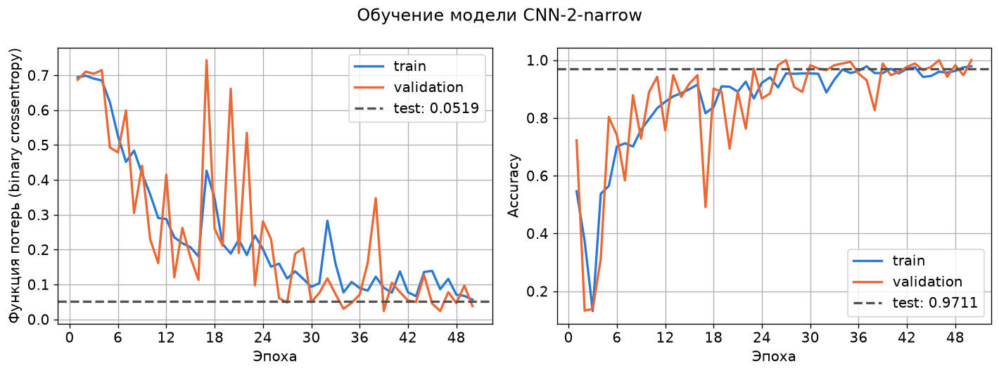

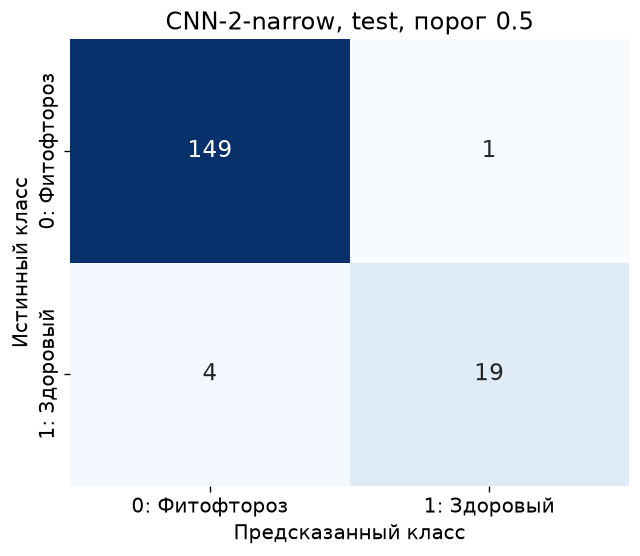

Ошибок на test: 5


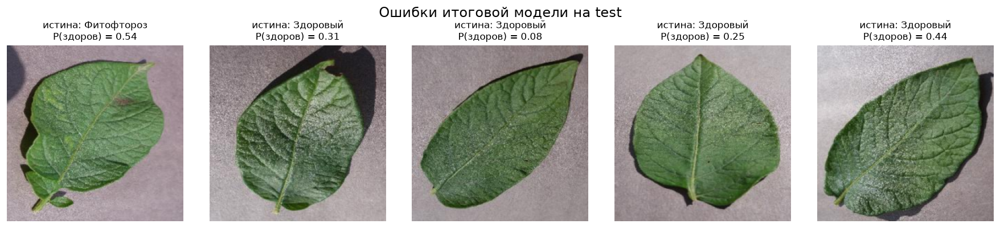

In [32]:
final_test_loss, final_test_accuracy = final_model.evaluate(X_test, y_test, batch_size=64, verbose=0)
print(f"Test loss {final_test_loss:.4f}, test accuracy (порог 0,5) {final_test_accuracy:.4f}")
plot_history(final_name, "binary-best-history.png",
             test_values={"loss": final_test_loss, "accuracy": final_test_accuracy})

final_test_probabilities = test_probabilities[final_name]
final_matrix = plot_confusion(y_test, (final_test_probabilities >= FINAL_THRESHOLD).astype(int),
                              f"{final_name}, test, порог {FINAL_THRESHOLD}", "binary-best-confusion.png")

# Ошибочные снимки теста: какие листья модель путает
error_indices = np.flatnonzero((final_test_probabilities >= FINAL_THRESHOLD).astype(int) != y_test)
print("Ошибок на test:", len(error_indices))
if len(error_indices) > 0:
    shown = error_indices[:8]
    figure, axes = plt.subplots(1, len(shown), figsize=(3 * len(shown), 3.4), squeeze=False)
    for axis, index in zip(axes[0], shown):
        axis.imshow(X_test[index])
        axis.set_title(f"истина: {CLASS_NAMES[y_test[index]]}\nP(здоров) = {final_test_probabilities[index]:.2f}", fontsize=10)
        axis.axis("off")
    figure.suptitle("Ошибки итоговой модели на test")
    figure.tight_layout()
    figure.savefig(FIGURES_DIR / "binary-best-errors.png")
    plt.show()

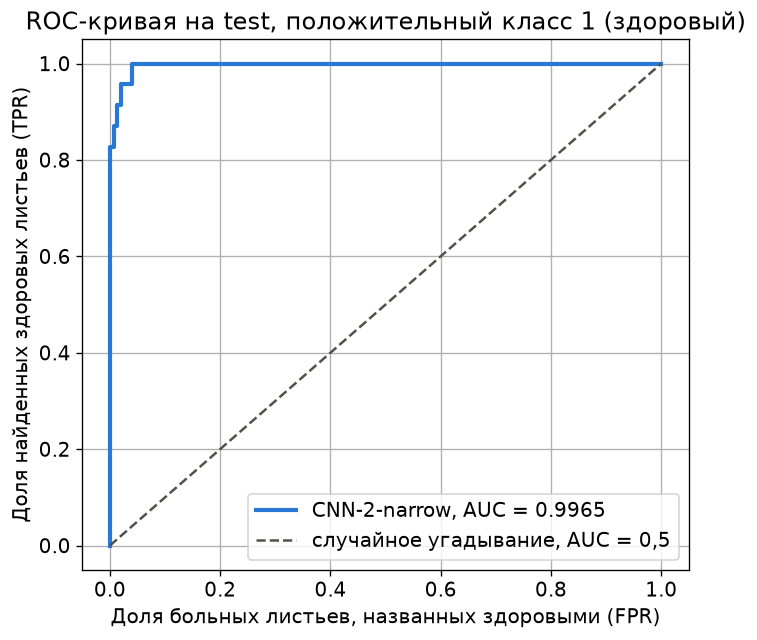

In [33]:
false_positive_rate, true_positive_rate, _ = roc_curve(y_test, final_test_probabilities)
final_auc = roc_auc_score(y_test, final_test_probabilities)
figure, axis = plt.subplots(figsize=(6, 5.5))
axis.plot(false_positive_rate, true_positive_rate, color=TRAIN_COLOR, linewidth=2.5, label=f"{final_name}, AUC = {final_auc:.4f}")
axis.plot([0, 1], [0, 1], color=TEST_COLOR, linestyle="--", label="случайное угадывание, AUC = 0,5")
axis.set_xlabel("Доля больных листьев, названных здоровыми (FPR)")
axis.set_ylabel("Доля найденных здоровых листьев (TPR)")
axis.set_title("ROC-кривая на test, положительный класс 1 (здоровый)")
axis.legend(loc="lower right")
figure.tight_layout()
figure.savefig(FIGURES_DIR / "binary-best-roc.png")
plt.show()

**Результат:** test loss 0,0519 (лучший val loss 0,0239). Кривые train и validation снижаются вместе, без расхождения, то есть без переобучения. Но val loss сильно скачет, особенно в первые 25 эпох (до 0,74 на 17-й эпохе): на validation всего 23 здоровых снимка, и небольшой сдвиг вероятностей сразу меняет ответы для многих из них, а вес 3,8 у здоровых снимков делает шаги обучения резкими. Поэтому patience 8 нужен с запасом, а выбор лучшей эпохи по val loss (46-я) отсекает скачки. На test 5 ошибок из 173: 4 здоровых листа из 23 названы больными (Recall 0,8261) и 1 лист с фитофторозом из 150 назван здоровым (Precision 0,95). ROC-AUC 0,9965: почти все здоровые листья получают более высокую оценку, чем больные, ошибки возникают у порога. Пропущенные здоровые листья покрыты светлыми зернистыми бликами (освещение отражается от поверхности листа), которые сеть принимает за налёт или пятна; лист с фитофторозом, названный здоровым, имеет всего одно маленькое пятно, и его оценка 0,54 лежит у самого порога. Класс 1 положительный: ROC-кривая показывает долю найденных здоровых листьев против доли больных, названных здоровыми.

## Вывод

1. **Данные.** Выделены три класса варианта 7 (1000 / 152 / 1000 снимков), повреждённых файлов и ошибок меток нет, все снимки 256 x 256 RGB. Найдена пара снимков одного листа, она помещена в одну выборку, чтобы исключить утечку. Разбиение 70 / 15 / 15 стратифицированное, списки файлов сохранены.
2. **Собственная CNN.** Бинарная задача (фитофтороз против здорового листа) решается хорошо: итоговая `CNN-2-narrow` (3 блока 16-32-64, GlobalAveragePooling, Dense 128, 32 033 параметра) на test даёт Accuracy 0,9711, Balanced Accuracy 0,9097, Precision 0,95, Recall 0,8261, ROC-AUC 0,9965. `Dummy`: Balanced Accuracy 0,5. Ориентир 0,80 превышен.
3. **Архитектура, фильтры, глубина, оптимизатор.** Простая сеть оказалась лучшей: больше фильтров (CNN-2) и больше блоков (CNN-2-deep) не улучшили val loss. CNN-1 с Flatten имеет 25,7 млн параметров, с шагом 0,001 не обучилась вовсе, а с шагом 0,0001 заучивает обучающие снимки. Adam 0,001 лучше RMSprop, SGD и Adam 0,0001. Разница между архитектурами (0,02 и больше по val loss) больше разброса между запусками (0,0069).
4. **Dropout.** Переобучение видно только у большой CNN-1 (train accuracy 1,0, val loss в 15 раз выше train loss). Dropout 0,3 уменьшил разрыв у CNN-1, но val loss почти не изменился. Для узкой сети Dropout 0,5 вреден: недообучение, val loss вырос с 0,0239 до 0,1190. Dropout был не нужен.
5. **Аугментация.** Применялась только к обучающим снимкам (слои внутри сети работают только в `fit`). На этом наборе она не помогла: снимки validation и test сняты однотипно, а искажения делают обучение труднее и в 5-19 раз дольше. Вариант с повтором здоровых снимков нашёл больше здоровых листьев, но чаще пропускал болезнь.
6. **Дисбаланс.** Веса классов (0,5757 и 3,8019) и порог 0,5, подобранный на validation, сохранены, но на этом наборе классы разделяются так хорошо, что сеть без весов работает так же.
7. **Лучшая модель** сохранена в `models/binary-best.keras` (вход 224 x 224 x 3, пиксели / 255, порог 0,5). Почему результат такой: болезнь видна по цвету и пятнам, а снимки сняты в одинаковых лабораторных условиях, поэтому небольшой сети хватает. Оставшиеся ошибки - здоровые листья со светлыми бликами на поверхности и лист с одним маленьким пятном; на полевых снимках с другим фоном качество, скорее всего, будет ниже.